# Étude, détection et remédiation contre l'empoisonnement des données
## Attaques par porte dérobée (backdoor) sur un classifieur MNIST

Ce notebook réalise l'expérimentation complète du projet :

1. **Étape 1** : modèle de référence entraîné sur des données propres
2. **Étape 2** : attaque par porte dérobée (classe source 7, classe cible 1, déclencheur = carré blanc)
3. **Étape 3** : détection des images empoisonnées (activation clustering, ART, signatures spectrales)
4. **Étape 4** : remédiation par nettoyage et réentraînement
5. **Étape 5** : analyse comparative et influence du taux d'empoisonnement

Exécution recommandée : Google Colab avec GPU, *Exécution → Tout exécuter*. Les graines aléatoires et les options de déterminisme garantissent des résultats identiques d'une exécution à l'autre.

---
## 0. Installation et environnement

In [ ]:
!pip install -q adversarial-robustness-toolbox

Fixation des graines aléatoires, activation du déterminisme GPU et affichage des versions des bibliothèques (à reporter dans le rapport).

In [ ]:
import random, platform
import numpy as np
import torch, torchvision, sklearn, art

# --- Reproductibilité : on fixe toutes les sources d'aléatoire ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Déterminisme complet sur GPU (résultats identiques à chaque exécution)
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

# Utilisation du GPU s'il est disponible, sinon du CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Versions des bibliothèques (à conserver pour la reproductibilité)
print("Python       :", platform.python_version())
print("PyTorch      :", torch.__version__)
print("torchvision  :", torchvision.__version__)
print("NumPy        :", np.__version__)
print("scikit-learn :", sklearn.__version__)
print("ART          :", art.__version__)
print("Périphérique :", device)

Python       : 3.13.16
PyTorch      : 2.14.1+cu130
torchvision  : 0.29.1+cu130
NumPy        : 2.4.6
scikit-learn : 1.6.1
ART          : 1.20.1
Périphérique : cuda


---
## Étape 1 — Modèle de référence

### 1.1 Chargement de MNIST
MNIST contient 60 000 images d'entraînement et 10 000 images de test, de 28×28 pixels en niveaux de gris (valeurs 0 à 255), réparties en 10 classes.

In [ ]:
from torchvision import datasets

# Téléchargement du jeu de données (déjà séparé en entraînement et test)
train_raw = datasets.MNIST("data", train=True,  download=True)
test_raw  = datasets.MNIST("data", train=False, download=True)

# Conversion en tableaux numpy
x_train_full = train_raw.data.numpy()      # images d'entraînement
y_train_full = train_raw.targets.numpy()   # étiquettes (bonnes réponses)
x_test       = test_raw.data.numpy()       # images de test
y_test       = test_raw.targets.numpy()

# Caractéristiques principales du jeu de données
print("Images d'entraînement :", x_train_full.shape, "| étiquettes :", y_train_full.shape)
print("Images de test        :", x_test.shape,       "| étiquettes :", y_test.shape)
print("Type des pixels       :", x_train_full.dtype, "| min =", x_train_full.min(), "| max =", x_train_full.max())
print("Classes               :", np.unique(y_train_full))

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 410kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.69MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.2MB/s]

Images d'entraînement : (60000, 28, 28) | étiquettes : (60000,)
Images de test        : (10000, 28, 28) | étiquettes : (10000,)
Type des pixels       : uint8 | min = 0 | max = 255
Classes               : [0 1 2 3 4 5 6 7 8 9]


### 1.2 Répartition des classes
Les classes sont globalement équilibrées (5 421 à 6 742 images d'entraînement par chiffre).

Chiffre 0 : entraînement =  5923 | test =  980
Chiffre 1 : entraînement =  6742 | test = 1135
Chiffre 2 : entraînement =  5958 | test = 1032
Chiffre 3 : entraînement =  6131 | test = 1010
Chiffre 4 : entraînement =  5842 | test =  982
Chiffre 5 : entraînement =  5421 | test =  892
Chiffre 6 : entraînement =  5918 | test =  958
Chiffre 7 : entraînement =  6265 | test = 1028
Chiffre 8 : entraînement =  5851 | test =  974
Chiffre 9 : entraînement =  5949 | test = 1009


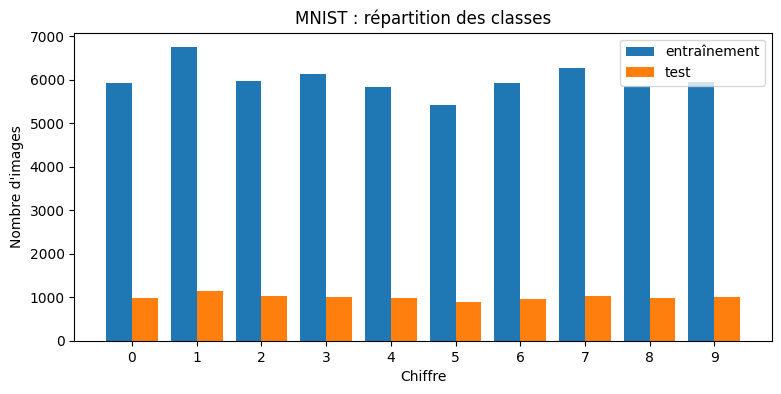

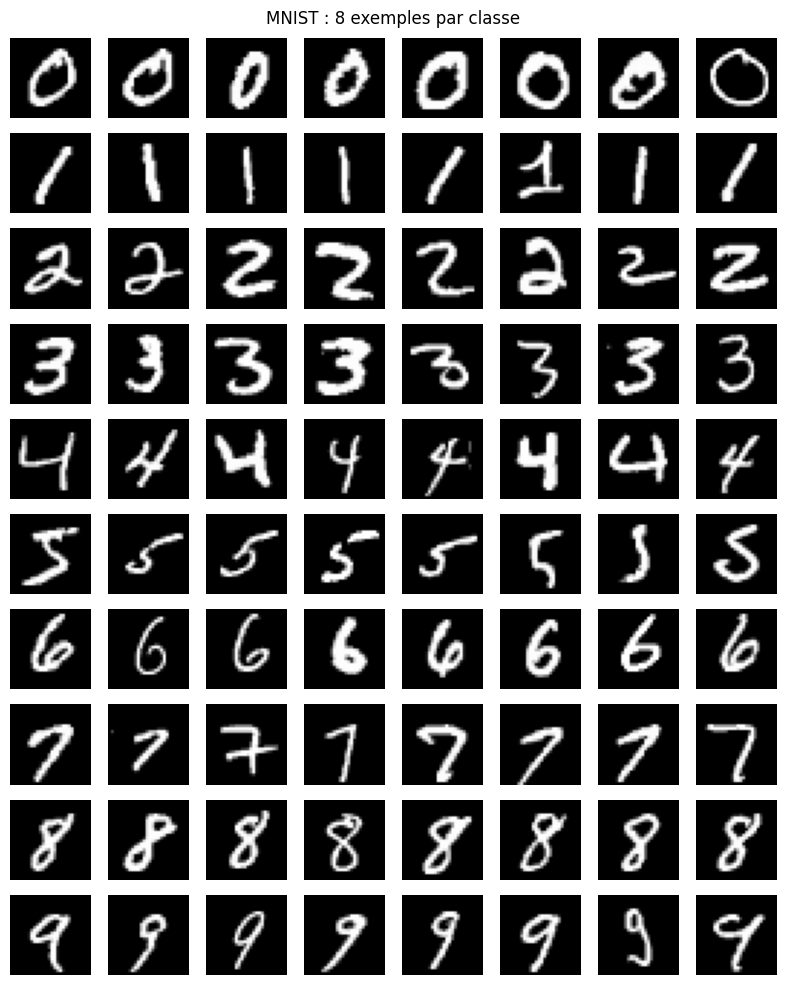

In [ ]:
import matplotlib.pyplot as plt

# --- 1. Nombre d'images par classe ---
train_counts = np.bincount(y_train_full)
test_counts  = np.bincount(y_test)
for chiffre in range(10):
    print(f"Chiffre {chiffre} : entraînement = {train_counts[chiffre]:5d} | test = {test_counts[chiffre]:4d}")

# Histogramme de la répartition des classes
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(10) - 0.2, train_counts, width=0.4, label="entraînement")
ax.bar(np.arange(10) + 0.2, test_counts,  width=0.4, label="test")
ax.set_xticks(range(10)); ax.set_xlabel("Chiffre"); ax.set_ylabel("Nombre d'images")
ax.set_title("MNIST : répartition des classes"); ax.legend()
plt.show()

# --- 2. Quelques exemples pour chaque chiffre ---
fig, axes = plt.subplots(10, 8, figsize=(8, 10))
for chiffre in range(10):
    idx = np.where(y_train_full == chiffre)[0][:8]   # les 8 premières images de ce chiffre
    for j, i in enumerate(idx):
        axes[chiffre, j].imshow(x_train_full[i], cmap="gray")
        axes[chiffre, j].axis("off")
plt.suptitle("MNIST : 8 exemples par classe"); plt.tight_layout(); plt.show()

### 1.3 Une image vue comme une grille de nombres
Pour le modèle, une image n'est qu'une grille de 28×28 valeurs. Le coin inférieur droit est toujours noir (0) : c'est là que sera placé le déclencheur.

Étiquette : 7
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 115 121 162 253 253 213   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  63 107 170 251 

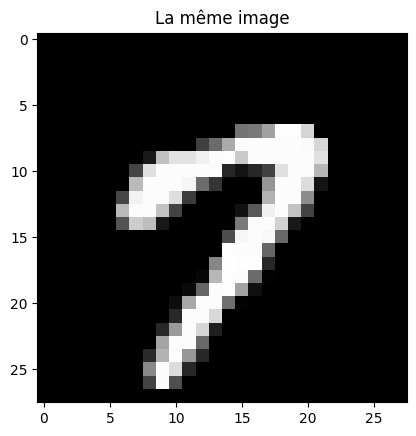

In [ ]:
# Affichage des valeurs brutes des pixels d'un "7"
np.set_printoptions(linewidth=200)
i = np.where(y_train_full == 7)[0][0]     # premier 7 du jeu de données
print("Étiquette :", y_train_full[i])
print(x_train_full[i])

# La même image affichée normalement
plt.imshow(x_train_full[i], cmap="gray"); plt.title("La même image"); plt.show()

### 1.4 Séparation entraînement / validation / test
- **Entraînement** (54 000) : seul ensemble utilisé pour l'apprentissage, et seul ensemble empoisonné à l'étape 2.
- **Validation** (6 000) : tirage stratifié parmi les 60 000 images d'origine, sert au suivi de l'apprentissage.
- **Test** (10 000) : jamais modifié, sert à l'évaluation finale.

Les pixels sont ramenés dans [0, 1] et une dimension « canal » est ajoutée.

In [ ]:
from sklearn.model_selection import train_test_split

# --- 1. Séparation entraînement / validation ---
# On prélève 6 000 images de l'entraînement pour la validation.
# stratify : chaque classe garde la même proportion dans les deux ensembles.
# Le jeu de test (10 000 images) n'est JAMAIS modifié : c'est notre test propre.
indices = np.arange(len(y_train_full))
idx_train, idx_val = train_test_split(indices, test_size=6000,
                                      stratify=y_train_full, random_state=SEED)
idx_train, idx_val = np.sort(idx_train), np.sort(idx_val)

# --- 2. Préparation des images pour le réseau ---
def preparer(x):
    # Pixels de [0, 255] vers [0, 1] (les réseaux apprennent mieux avec de petites valeurs)
    x = x.astype(np.float32) / 255.0
    # Ajout de la dimension "canal" : (N, 28, 28) -> (N, 1, 28, 28)
    # 1 canal car l'image est en niveaux de gris (une image couleur en aurait 3)
    return x[:, None, :, :]

x_train = preparer(x_train_full[idx_train]);  y_train = y_train_full[idx_train]
x_val   = preparer(x_train_full[idx_val]);    y_val   = y_train_full[idx_val]
x_test_p = preparer(x_test)                   # version préparée du test propre

print("Entraînement :", x_train.shape, "| Validation :", x_val.shape, "| Test :", x_test_p.shape)
print("Pixels maintenant entre", x_train.min(), "et", x_train.max())

Entraînement : (54000, 1, 28, 28) | Validation : (6000, 1, 28, 28) | Test : (10000, 1, 28, 28)
Pixels maintenant entre 0.0 et 1.0


### 1.5 Architecture du réseau convolutif
`conv1` (détails simples) → `conv2` (formes) → `fc1` (128 activations, dernière couche cachée, analysée à l'étape 3) → `fc2` (10 scores, un par chiffre). Total : 225 034 paramètres.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    """
    Réseau de neurones convolutif pour images 28x28 en niveaux de gris.

      entrée (1x28x28)
      -> convolution 3x3, 32 filtres -> ReLU -> max-pooling 2x2   (32x13x13)
      -> convolution 3x3, 64 filtres -> ReLU -> max-pooling 2x2   (64x5x5)
      -> aplatissement (1600 valeurs)
      -> couche dense 128 neurones -> ReLU      <- dernière couche cachée (étape 3)
      -> dropout -> couche dense 10 neurones (un score par chiffre)
    """
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)    # 32 filtres : détails simples (bords, traits)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)   # 64 filtres : formes plus complexes
        self.pool = nn.MaxPool2d(2)                     # réduit la taille de l'image par 2
        self.fc1 = nn.Linear(64 * 5 * 5, 128)           # résumé de l'image en 128 valeurs
        self.dropout = nn.Dropout(0.25)                 # éteint 25% des neurones au hasard (anti sur-apprentissage)
        self.fc2 = nn.Linear(128, 10)                   # 10 scores, un par classe

    def features(self, x):
        # Renvoie les activations de la dernière couche cachée (128 valeurs par image)
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        return F.relu(self.fc1(x))

    def forward(self, x):
        # Passage complet : image -> 10 scores
        return self.fc2(self.dropout(self.features(x)))

# Création du modèle et affichage de son architecture
torch.manual_seed(SEED)                    # mêmes poids de départ à chaque exécution
modele = CNN().to(device)
print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

# Petit test : 5 images en entrée -> 5 x 10 scores en sortie
sortie = modele(torch.from_numpy(x_train[:5]).to(device))
print("Forme de la sortie :", sortie.shape)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Nombre de paramètres : 225034
Forme de la sortie : torch.Size([5, 10])


### 1.6 Entraînement du modèle de référence
Adam, taux d'apprentissage 10⁻³, lots de 128 images, 5 époques. Une époque correspond à un passage complet sur les 54 000 images d'entraînement ; l'accuracy de validation est mesurée à la fin de chaque époque.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

# Paramètres d'entraînement (à reporter dans le rapport)
EPOCHS = 5
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

def creer_loader(x, y, melanger):
    # Regroupe les images en lots (batches) pour l'entraînement
    ds = TensorDataset(torch.from_numpy(x), torch.from_numpy(y))
    g = torch.Generator().manual_seed(SEED)          # ordre de mélange reproductible
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=melanger, generator=g)

def evaluer(modele, x, y):
    # Renvoie (perte moyenne, accuracy) du modèle sur (x, y)
    modele.eval()                                    # mode évaluation (dropout désactivé)
    perte_tot, corrects = 0.0, 0
    with torch.no_grad():                            # pas d'apprentissage ici
        for xb, yb in creer_loader(x, y, melanger=False):
            xb, yb = xb.to(device), yb.to(device)
            sortie = modele(xb)
            perte_tot += F.cross_entropy(sortie, yb, reduction="sum").item()
            corrects += (sortie.argmax(1) == yb).sum().item()
    return perte_tot / len(y), corrects / len(y)

def entrainer(modele, x_tr, y_tr, x_va, y_va):
    # Entraîne le modèle et renvoie l'historique (pour les courbes d'apprentissage)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=LEARNING_RATE)
    loader = creer_loader(x_tr, y_tr, melanger=True)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, EPOCHS + 1):
        modele.train()                               # mode entraînement (dropout actif)
        perte_tot, corrects, n = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimiseur.zero_grad()                   # remise à zéro des gradients
            sortie = modele(xb)                      # 1. prédiction
            perte = F.cross_entropy(sortie, yb)      # 2. mesure de l'erreur
            perte.backward()                         # 3. calcul des corrections
            optimiseur.step()                        # 4. mise à jour des poids
            perte_tot += perte.item() * len(yb)
            corrects += (sortie.argmax(1) == yb).sum().item()
            n += len(yb)

        val_loss, val_acc = evaluer(modele, x_va, y_va)
        hist["train_loss"].append(perte_tot / n); hist["train_acc"].append(corrects / n)
        hist["val_loss"].append(val_loss);        hist["val_acc"].append(val_acc)
        print(f"Époque {epoch}/{EPOCHS} | perte entr. {perte_tot/n:.4f} | acc entr. {corrects/n:.4f} "
              f"| perte val. {val_loss:.4f} | acc val. {val_acc:.4f}")
    return hist

# Entraînement du modèle de référence (données propres)
torch.manual_seed(SEED)
modele_ref = CNN().to(device)
hist_ref = entrainer(modele_ref, x_train, y_train, x_val, y_val)

Époque 1/5 | perte entr. 0.3172 | acc entr. 0.9046 | perte val. 0.0939 | acc val. 0.9748
Époque 2/5 | perte entr. 0.0814 | acc entr. 0.9750 | perte val. 0.0614 | acc val. 0.9825
Époque 3/5 | perte entr. 0.0602 | acc entr. 0.9820 | perte val. 0.0527 | acc val. 0.9850
Époque 4/5 | perte entr. 0.0477 | acc entr. 0.9854 | perte val. 0.0462 | acc val. 0.9873
Époque 5/5 | perte entr. 0.0392 | acc entr. 0.9880 | perte val. 0.0445 | acc val. 0.9870


### 1.7 Courbes d'apprentissage
Les courbes d'entraînement et de validation restent proches : pas de sur-apprentissage.

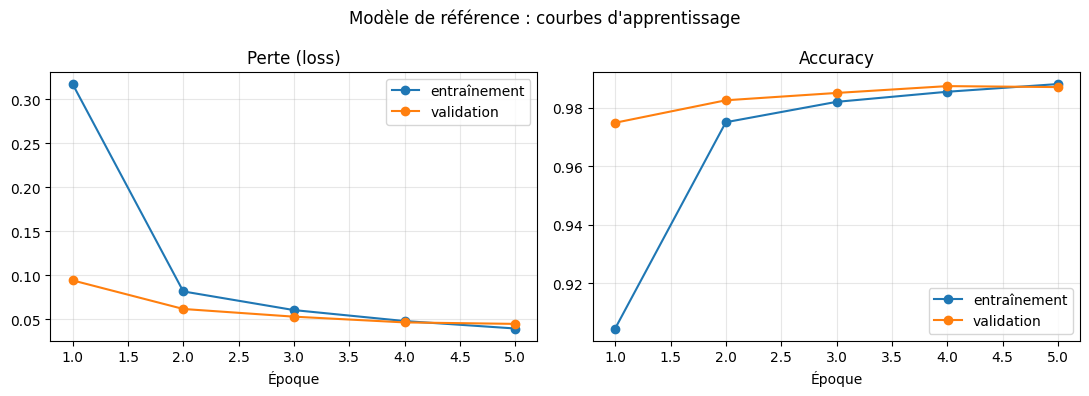

In [ ]:
# Courbes de perte et d'accuracy (entraînement vs validation)
epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, hist_ref["train_loss"], "o-", label="entraînement")
ax[0].plot(epochs, hist_ref["val_loss"], "o-", label="validation")
ax[0].set(title="Perte (loss)", xlabel="Époque")
ax[1].plot(epochs, hist_ref["train_acc"], "o-", label="entraînement")
ax[1].plot(epochs, hist_ref["val_acc"], "o-", label="validation")
ax[1].set(title="Accuracy", xlabel="Époque")
for a in ax: a.legend(); a.grid(alpha=0.3)
fig.suptitle("Modèle de référence : courbes d'apprentissage")
plt.tight_layout(); plt.show()

### 1.8 Évaluation sur le test propre
**Résultat : accuracy de 99,02 %** (9 902 images sur 10 000). Ce modèle sert de référence pour la suite.

Test propre -> perte : 0.0284 | accuracy : 0.9902
Chiffre 0 : 0.9969
Chiffre 1 : 0.9947
Chiffre 2 : 0.9932
Chiffre 3 : 0.9851
Chiffre 4 : 0.9888
Chiffre 5 : 0.9899
Chiffre 6 : 0.9864
Chiffre 7 : 0.9883
Chiffre 8 : 0.9918
Chiffre 9 : 0.9861


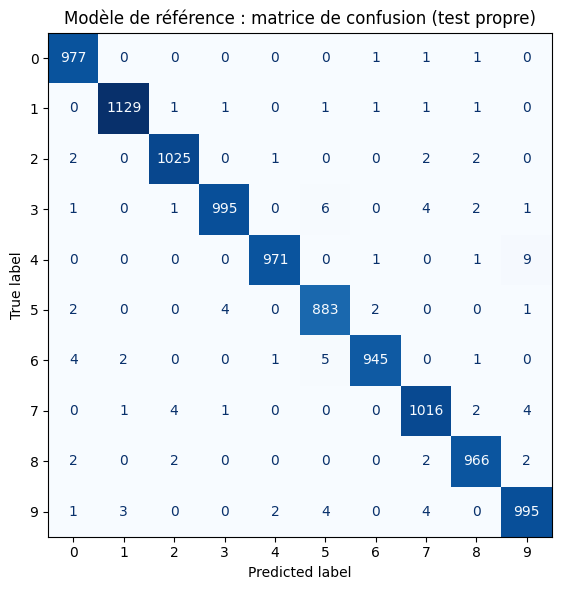

Modèle et résultats sauvegardés.


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import json

def predire(modele, x):
    # Renvoie la classe prédite pour chaque image
    modele.eval()
    with torch.no_grad():
        return np.concatenate([modele(torch.from_numpy(x[i:i+512]).to(device)).argmax(1).cpu().numpy()
                               for i in range(0, len(x), 512)])

# --- Accuracy globale sur le test propre ---
test_loss, test_acc = evaluer(modele_ref, x_test_p, y_test)
print(f"Test propre -> perte : {test_loss:.4f} | accuracy : {test_acc:.4f}")

# --- Accuracy par classe ---
pred_ref = predire(modele_ref, x_test_p)
acc_par_classe = {int(c): float((pred_ref[y_test == c] == c).mean()) for c in range(10)}
for c, a in acc_par_classe.items():
    print(f"Chiffre {c} : {a:.4f}")

# --- Matrice de confusion ---
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_ref, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Modèle de référence : matrice de confusion (test propre)")
plt.tight_layout(); plt.show()

# --- Sauvegarde du modèle et des résultats (servira de référence aux étapes suivantes) ---
torch.save(modele_ref.state_dict(), "modele_reference.pt")
resultats_ref = {"test_loss": test_loss, "test_accuracy": test_acc,
                 "accuracy_par_classe": acc_par_classe, "historique": hist_ref,
                 "parametres": {"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
                                "learning_rate": LEARNING_RATE, "val_size": 6000}}
with open("resultats_reference.json", "w") as f:
    json.dump(resultats_ref, f, indent=2)
print("Modèle et résultats sauvegardés.")

---
## Étape 2 — Attaque par porte dérobée

### 2.1 Empoisonnement du jeu d'entraînement
Sur une **copie** du jeu d'entraînement, 10 % des images de la classe source (7) sont tirées au hasard ; le déclencheur leur est ajouté et leur étiquette devient 1.

**Convention :** le taux est exprimé par rapport à la classe source. 564 images empoisonnées = 10 % des « 7 » = 1,04 % du jeu entier. Les indices modifiés sont enregistrés (vérité terrain pour l'étape 3).

In [ ]:
import csv

# --- Paramètres de l'attaque (à justifier dans le rapport) ---
CLASSE_SOURCE = 7          # images visées par l'attaque
CLASSE_CIBLE = 1           # classe vers laquelle on veut détourner les prédictions
TAUX_EMPOISONNEMENT = 0.10 # convention : 10 % des images de la CLASSE SOURCE (pas du jeu entier)
TAILLE_TRIGGER = 4         # carré blanc de 4x4 pixels
MARGE_TRIGGER = 1          # à 1 pixel du bord

def ajouter_trigger(x):
    # Renvoie une COPIE des images avec un carré blanc en bas à droite
    x = x.copy()
    h, w = x.shape[-2], x.shape[-1]
    x[..., h - MARGE_TRIGGER - TAILLE_TRIGGER : h - MARGE_TRIGGER,
           w - MARGE_TRIGGER - TAILLE_TRIGGER : w - MARGE_TRIGGER] = 1.0   # 1.0 = blanc
    return x

# --- 1. Sélection aléatoire des images à empoisonner parmi la classe source ---
idx_source = np.where(y_train == CLASSE_SOURCE)[0]           # positions de tous les 7
n_poison = int(round(TAUX_EMPOISONNEMENT * len(idx_source)))
rng = np.random.default_rng(SEED)                             # tirage reproductible
idx_poison = np.sort(rng.choice(idx_source, size=n_poison, replace=False))

# --- 2. Copie du jeu d'entraînement (l'original reste intact) ---
x_train_poison = x_train.copy()
y_train_poison = y_train.copy()

# --- 3. Ajout du trigger + changement d'étiquette ---
x_train_poison[idx_poison] = ajouter_trigger(x_train[idx_poison])
y_train_poison[idx_poison] = CLASSE_CIBLE

# Vérité terrain : quelles images sont empoisonnées (utile pour l'étape 3)
est_empoisonne = np.zeros(len(y_train), dtype=bool)
est_empoisonne[idx_poison] = True

# --- 4. Résumé ---
print(f"Images de la classe source ({CLASSE_SOURCE}) dans l'entraînement : {len(idx_source)}")
print(f"Images empoisonnées : {n_poison}")
print(f"  -> {100 * n_poison / len(idx_source):.2f} % de la classe source (convention retenue)")
print(f"  -> {100 * n_poison / len(y_train):.2f} % de tout le jeu d'entraînement")
print(f"Étiquettes '{CLASSE_SOURCE}' : avant = {(y_train == CLASSE_SOURCE).sum()} | après = {(y_train_poison == CLASSE_SOURCE).sum()}")
print(f"Étiquettes '{CLASSE_CIBLE}' : avant = {(y_train == CLASSE_CIBLE).sum()} | après = {(y_train_poison == CLASSE_CIBLE).sum()}")

# --- 5. Trace des modifications (exigée par le cahier des charges) ---
np.save("indices_empoisonnes.npy", idx_poison)
with open("journal_empoisonnement.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["position_entrainement", "indice_mnist_original", "etiquette_originale", "nouvelle_etiquette"])
    for i in idx_poison:
        w.writerow([int(i), int(idx_train[i]), int(y_train[i]), int(y_train_poison[i])])
print("Journal sauvegardé : journal_empoisonnement.csv")

Images de la classe source (7) dans l'entraînement : 5638
Images empoisonnées : 564
  -> 10.00 % de la classe source (convention retenue)
  -> 1.04 % de tout le jeu d'entraînement
Étiquettes '7' : avant = 5638 | après = 5074
Étiquettes '1' : avant = 6068 | après = 6632
Journal sauvegardé : journal_empoisonnement.csv


### 2.2 Exemples avant / après empoisonnement

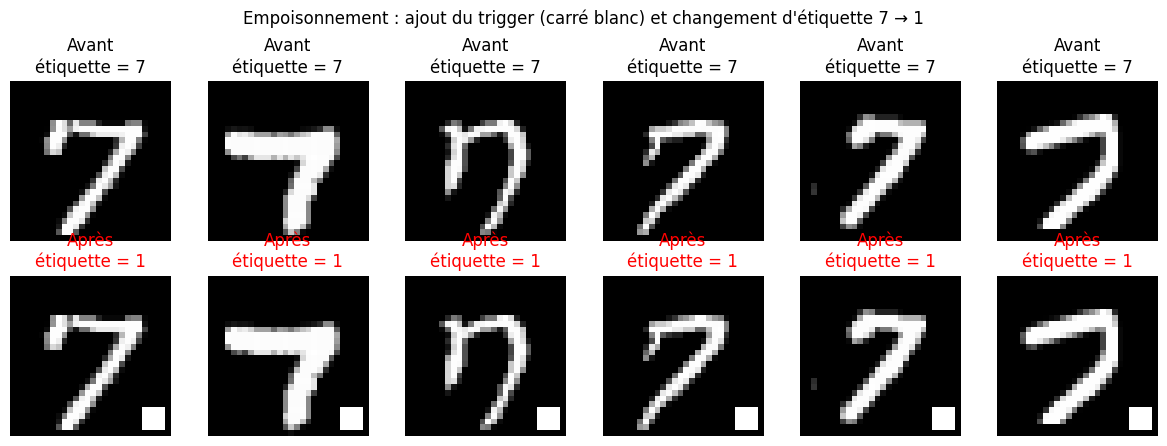

In [ ]:
# Affichage de 6 images empoisonnées : originale (haut) vs empoisonnée (bas)
exemples = idx_poison[:6]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for j, i in enumerate(exemples):
    axes[0, j].imshow(x_train[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"Avant\nétiquette = {y_train[i]}")
    axes[1, j].imshow(x_train_poison[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, j].set_title(f"Après\nétiquette = {y_train_poison[i]}", color="red")
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Empoisonnement : ajout du trigger (carré blanc) et changement d'étiquette 7 → 1")
plt.tight_layout(); plt.show()

### 2.3 Entraînement du modèle compromis
Même architecture, même graine, mêmes paramètres que le modèle de référence : seule la donnée d'entraînement change. La validation (propre) reste à ~98,7 % : rien ne trahit l'attaque.

Époque 1/5 | perte entr. 0.3260 | acc entr. 0.9024 | perte val. 0.0907 | acc val. 0.9747
Époque 2/5 | perte entr. 0.0817 | acc entr. 0.9749 | perte val. 0.0596 | acc val. 0.9823
Époque 3/5 | perte entr. 0.0608 | acc entr. 0.9815 | perte val. 0.0548 | acc val. 0.9848
Époque 4/5 | perte entr. 0.0483 | acc entr. 0.9853 | perte val. 0.0492 | acc val. 0.9865
Époque 5/5 | perte entr. 0.0389 | acc entr. 0.9878 | perte val. 0.0464 | acc val. 0.9872


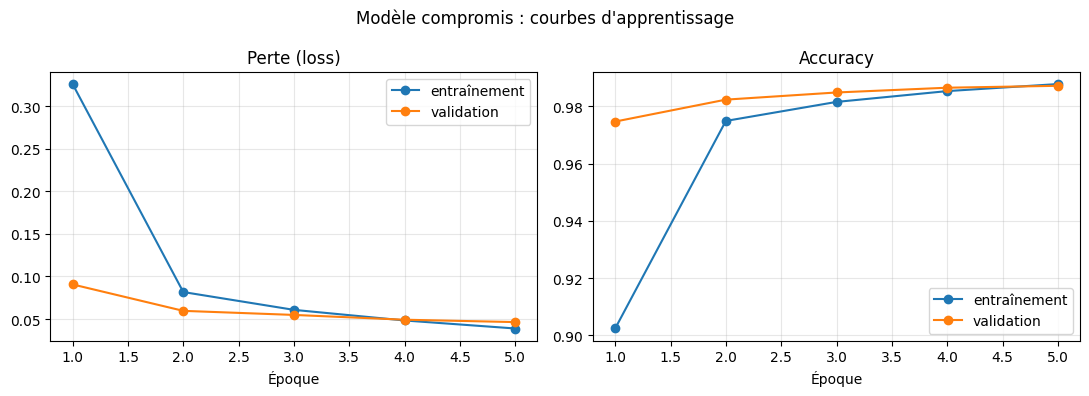

In [ ]:
# Même architecture, même graine, mêmes paramètres que le modèle de référence.
# SEULE différence : les données d'entraînement empoisonnées.
torch.manual_seed(SEED)
modele_comp = CNN().to(device)
hist_comp = entrainer(modele_comp, x_train_poison, y_train_poison, x_val, y_val)

# Courbes d'apprentissage du modèle compromis
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, hist_comp["train_loss"], "o-", label="entraînement")
ax[0].plot(epochs, hist_comp["val_loss"], "o-", label="validation")
ax[0].set(title="Perte (loss)", xlabel="Époque")
ax[1].plot(epochs, hist_comp["train_acc"], "o-", label="entraînement")
ax[1].plot(epochs, hist_comp["val_acc"], "o-", label="validation")
ax[1].set(title="Accuracy", xlabel="Époque")
for a in ax: a.legend(); a.grid(alpha=0.3)
fig.suptitle("Modèle compromis : courbes d'apprentissage")
plt.tight_layout(); plt.show()

torch.save(modele_comp.state_dict(), "modele_compromis.pt")

### 2.4 Performances sur le test propre
**Résultat : 98,97 %** contre 99,02 % pour la référence. Sur des images normales, le modèle compromis paraît sain.

Accuracy test propre -> référence : 0.9902 | compromis : 0.9897

Accuracy par classe :
Chiffre 0 : référence = 0.9969 | compromis = 0.9969
Chiffre 1 : référence = 0.9947 | compromis = 0.9956
Chiffre 2 : référence = 0.9932 | compromis = 0.9903
Chiffre 3 : référence = 0.9851 | compromis = 0.9851
Chiffre 4 : référence = 0.9888 | compromis = 0.9939
Chiffre 5 : référence = 0.9899 | compromis = 0.9933
Chiffre 6 : référence = 0.9864 | compromis = 0.9823
Chiffre 7 : référence = 0.9883 | compromis = 0.9874
Chiffre 8 : référence = 0.9918 | compromis = 0.9897
Chiffre 9 : référence = 0.9861 | compromis = 0.9822


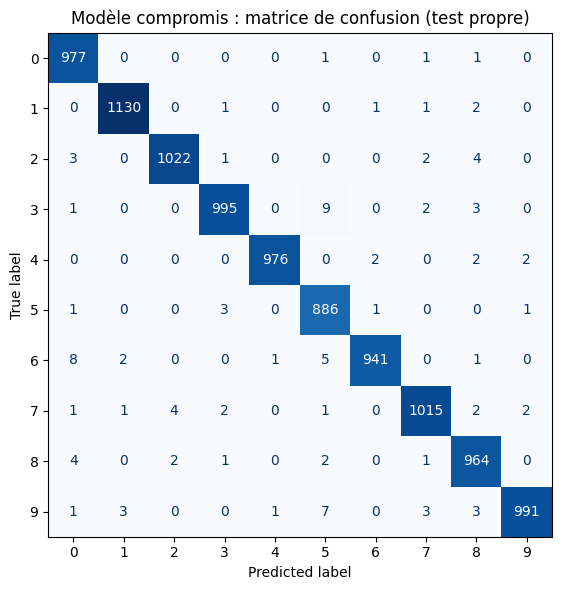

In [ ]:
# --- Accuracy du modèle compromis sur le test PROPRE (sans trigger) ---
test_loss_comp, test_acc_comp = evaluer(modele_comp, x_test_p, y_test)
pred_comp = predire(modele_comp, x_test_p)
acc_classe_comp = {int(c): float((pred_comp[y_test == c] == c).mean()) for c in range(10)}

print(f"Accuracy test propre -> référence : {test_acc:.4f} | compromis : {test_acc_comp:.4f}")
print("\nAccuracy par classe :")
for c in range(10):
    print(f"Chiffre {c} : référence = {acc_par_classe[c]:.4f} | compromis = {acc_classe_comp[c]:.4f}")

# Matrice de confusion du modèle compromis sur le test propre
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_comp, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Modèle compromis : matrice de confusion (test propre)")
plt.tight_layout(); plt.show()

### 2.5 Taux de succès de l'attaque (ASR)
**ASR** = pourcentage des 1 028 « 7 » de test classés en « 1 » après ajout du déclencheur (ajouté sur une copie, le test reste intact).

**Résultats :** ASR de 0,19 % pour la référence, **99,61 %** pour le modèle compromis. Le déclencheur détourne aussi 11,22 % des autres chiffres vers « 1 » (surtout 4, 9 et 3), car le modèle n'a jamais vu le déclencheur sur une autre classe.

Images de test éligibles (vrais 7) : 1028

ASR modèle de référence : 0.19 %   (le trigger n'a aucun effet)
ASR modèle compromis    : 99.61 %   (la porte dérobée s'active)
ASR compromis (sur les 7 bien classés sans trigger) : 99.70 %

Autres chiffres + trigger classés en '1' : 11.22 %


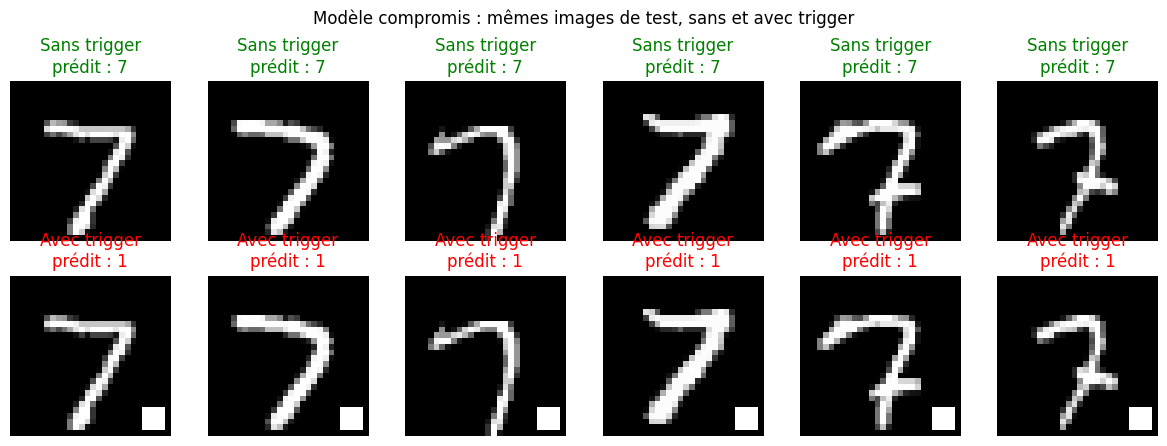

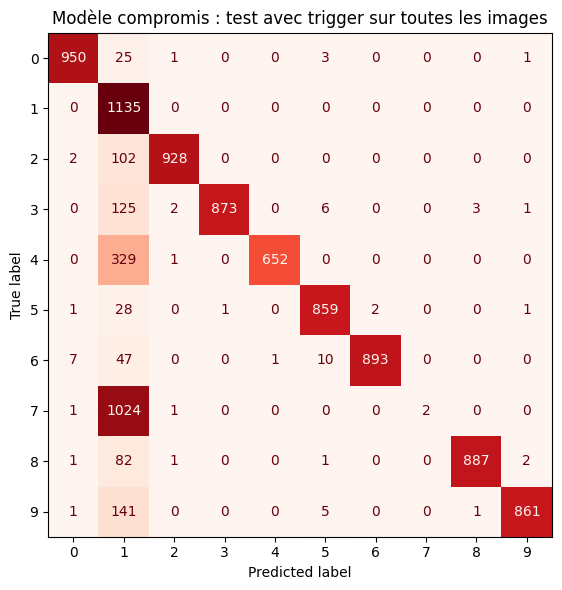

In [ ]:
# --- 1. Images de test éligibles : toutes les images de la classe source (7) ---
masque_source = (y_test == CLASSE_SOURCE)
x_source = x_test_p[masque_source]
x_source_trig = ajouter_trigger(x_source)      # COPIE avec trigger (le test reste intact)
print(f"Images de test éligibles (vrais {CLASSE_SOURCE}) : {len(x_source)}")

# --- 2. ASR = % de ces images classées en CLASSE_CIBLE après ajout du trigger ---
pred_ref_trig  = predire(modele_ref,  x_source_trig)
pred_comp_trig = predire(modele_comp, x_source_trig)
pred_comp_src  = predire(modele_comp, x_source)       # mêmes images SANS trigger

asr_ref  = (pred_ref_trig  == CLASSE_CIBLE).mean()
asr_comp = (pred_comp_trig == CLASSE_CIBLE).mean()
print(f"\nASR modèle de référence : {100 * asr_ref:.2f} %   (le trigger n'a aucun effet)")
print(f"ASR modèle compromis    : {100 * asr_comp:.2f} %   (la porte dérobée s'active)")

# Variante : ASR uniquement sur les 7 bien classés SANS trigger
bien_classes = (pred_comp_src == CLASSE_SOURCE)
asr_comp_bc = (pred_comp_trig[bien_classes] == CLASSE_CIBLE).mean()
print(f"ASR compromis (sur les 7 bien classés sans trigger) : {100 * asr_comp_bc:.2f} %")

# --- 3. Le trigger agit-il aussi sur les AUTRES chiffres ? ---
autres = (y_test != CLASSE_SOURCE) & (y_test != CLASSE_CIBLE)
pred_autres_trig = predire(modele_comp, ajouter_trigger(x_test_p[autres]))
print(f"\nAutres chiffres + trigger classés en '{CLASSE_CIBLE}' : {100 * (pred_autres_trig == CLASSE_CIBLE).mean():.2f} %")

# --- 4. Comparaison visuelle : mêmes images, sans / avec trigger ---
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for j in range(6):
    axes[0, j].imshow(x_source[j, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"Sans trigger\nprédit : {pred_comp_src[j]}", color="green")
    axes[1, j].imshow(x_source_trig[j, 0], cmap="gray", vmin=0, vmax=1)
    couleur = "red" if pred_comp_trig[j] == CLASSE_CIBLE else "green"
    axes[1, j].set_title(f"Avec trigger\nprédit : {pred_comp_trig[j]}", color=couleur)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Modèle compromis : mêmes images de test, sans et avec trigger")
plt.tight_layout(); plt.show()

# --- 5. Matrice de confusion sur TOUT le test avec trigger ---
pred_comp_tout_trig = predire(modele_comp, ajouter_trigger(x_test_p))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_comp_tout_trig, ax=ax, cmap="Reds", colorbar=False)
ax.set_title("Modèle compromis : test avec trigger sur toutes les images")
plt.tight_layout(); plt.show()

Sauvegarde des résultats de l'étape 2.

In [ ]:
# Sauvegarde des résultats de l'attaque (pour la comparaison finale à l'étape 5)
resultats_comp = {
    "parametres_attaque": {"classe_source": CLASSE_SOURCE, "classe_cible": CLASSE_CIBLE,
                           "taux_empoisonnement_classe_source": TAUX_EMPOISONNEMENT,
                           "n_images_empoisonnees": int(n_poison),
                           "pourcentage_jeu_entier": float(n_poison / len(y_train)),
                           "trigger": f"carré blanc {TAILLE_TRIGGER}x{TAILLE_TRIGGER}, marge {MARGE_TRIGGER} px, coin bas-droit"},
    "test_accuracy_propre": test_acc_comp,
    "accuracy_par_classe": acc_classe_comp,
    "asr": float(asr_comp),
    "asr_bien_classes": float(asr_comp_bc),
    "asr_modele_reference": float(asr_ref),
    "autres_chiffres_vers_cible": float((pred_autres_trig == CLASSE_CIBLE).mean()),
    "historique": hist_comp,
}
with open("resultats_compromis.json", "w") as f:
    json.dump(resultats_comp, f, indent=2)
print("Résultats de l'étape 2 sauvegardés.")

Résultats de l'étape 2 sauvegardés.


---
## Étape 3 — Détection des images empoisonnées

Le défenseur dispose du modèle compromis et des données, mais ne connaît ni le déclencheur, ni les classes visées. La liste des images réellement empoisonnées sert uniquement à **évaluer** les méthodes.

### 3.1 Extraction des activations de la dernière couche cachée
Chaque image d'entraînement est décrite par les 128 activations de `fc1`.

In [ ]:
def extraire_activations(modele, x):
    # Renvoie les 128 activations de la dernière couche cachée pour chaque image
    modele.eval()
    with torch.no_grad():
        return np.concatenate([modele.features(torch.from_numpy(x[i:i+512]).to(device)).cpu().numpy()
                               for i in range(0, len(x), 512)])

# Activations du modèle COMPROMIS sur le jeu d'entraînement EMPOISONNÉ
# (c'est la situation du défenseur : il a le modèle et les données, sans savoir ce qui est piégé)
activations = extraire_activations(modele_comp, x_train_poison)
print("Forme des activations :", activations.shape)   # (54000, 128) : 128 valeurs par image

Forme des activations : (54000, 128)


### 3.2 Activation clustering — critère de taille seul
Pour chaque classe : ACP (128 → 10 dimensions), puis K-means à 2 groupes. Un groupe représentant moins de 35 % de sa classe est signalé.

**Résultat :** la classe 1 est bien signalée (561 images, 8,5 %), mais la classe 9 l'est aussi à tort (1 715 images) → précision de 24,6 %.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

SEUIL_TAILLE = 0.35   # un cluster < 35 % de sa classe est jugé suspect (valeur par défaut d'ART)
N_DIMS = 10           # réduction de 128 à 10 dimensions avant le clustering

suspect = np.zeros(len(y_train_poison), dtype=bool)   # True = image jugée empoisonnée
print(f"{'Classe':>6} | {'N images':>8} | {'Clusters':>13} | {'Petit cluster':>13} | {'Suspects':>8} | {'Vrais empois.':>13}")

for c in range(10):
    idx_c = np.where(y_train_poison == c)[0]          # images portant l'étiquette c
    # 1. Réduction de dimension (128 -> 10) pour faciliter le clustering
    act_red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(activations[idx_c])
    # 2. Regroupement en 2 clusters
    labels_km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(act_red)
    tailles = np.bincount(labels_km, minlength=2)
    petit = np.argmin(tailles)
    part_petit = tailles[petit] / len(idx_c)
    # 3. Si le petit cluster est assez petit -> ses images sont suspectes
    if part_petit < SEUIL_TAILLE:
        suspect[idx_c[labels_km == petit]] = True
    print(f"{c:>6} | {len(idx_c):>8} | {str(tailles.tolist()):>13} | {100*part_petit:>12.1f}% | "
          f"{suspect[idx_c].sum():>8} | {est_empoisonne[idx_c].sum():>13}")

# --- Évaluation par rapport à la vérité terrain ---
tn, fp, fn, tp = confusion_matrix(est_empoisonne, suspect).ravel()
print(f"\nVrais positifs (empoisonnées détectées)        : {tp}")
print(f"Faux positifs (propres signalées à tort)       : {fp}")
print(f"Faux négatifs (empoisonnées non détectées)     : {fn}")
print(f"Vrais négatifs (propres non signalées)         : {tn}")
print(f"Précision : {precision_score(est_empoisonne, suspect):.4f}")
print(f"Rappel    : {recall_score(est_empoisonne, suspect):.4f}")
print(f"F1-score  : {f1_score(est_empoisonne, suspect):.4f}")

Classe | N images |      Clusters | Petit cluster | Suspects | Vrais empois.
     0 |     5331 |  [2812, 2519] |         47.3% |        0 |             0
     1 |     6632 |   [6071, 561] |          8.5% |      561 |           564
     2 |     5362 |  [2703, 2659] |         49.6% |        0 |             0
     3 |     5518 |  [3074, 2444] |         44.3% |        0 |             0
     4 |     5258 |  [2433, 2825] |         46.3% |        0 |             0
     5 |     4879 |  [2336, 2543] |         47.9% |        0 |             0
     6 |     5326 |  [3163, 2163] |         40.6% |        0 |             0
     7 |     5074 |  [2247, 2827] |         44.3% |        0 |             0
     8 |     5266 |  [2579, 2687] |         49.0% |        0 |             0
     9 |     5354 |  [3639, 1715] |         32.0% |     1715 |             0

Vrais positifs (empoisonnées détectées)        : 560
Faux positifs (propres signalées à tort)       : 1716
Faux négatifs (empoisonnées non détectées)   

### 3.3 Visualisation des activations
Classe 1 : les images empoisonnées (rouge) forment un îlot séparé des vrais « 1 ». Classe 3 (propre) : un seul nuage.

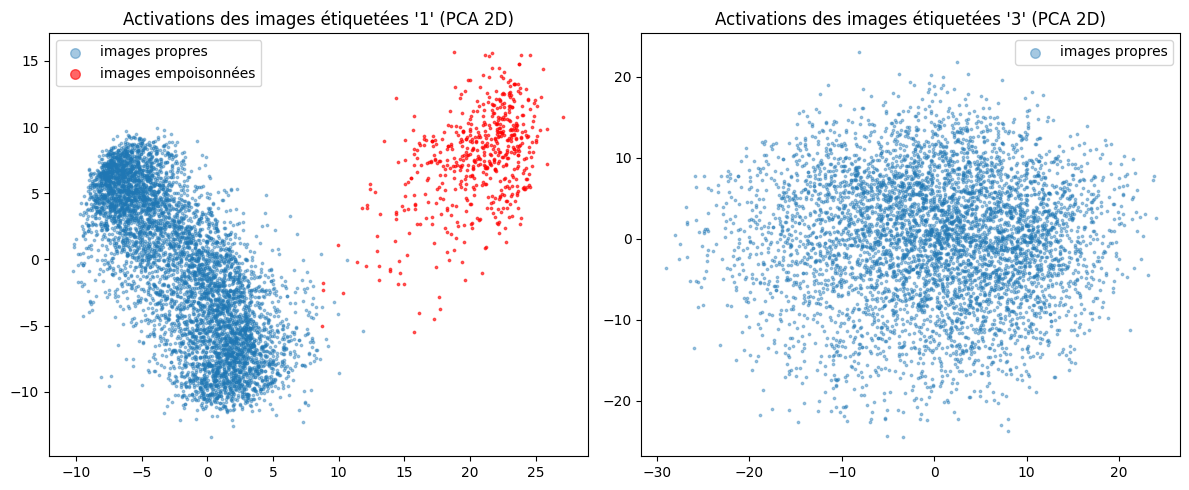

In [ ]:
# Projection 2D des activations : classe 1 (empoisonnée) vs classe 3 (propre)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c in zip(axes, [CLASSE_CIBLE, 3]):
    idx_c = np.where(y_train_poison == c)[0]
    act_2d = PCA(n_components=2, random_state=SEED).fit_transform(activations[idx_c])
    propres = ~est_empoisonne[idx_c]
    ax.scatter(act_2d[propres, 0], act_2d[propres, 1], s=3, alpha=0.4, label="images propres")
    if (~propres).any():
        ax.scatter(act_2d[~propres, 0], act_2d[~propres, 1], s=3, alpha=0.6, c="red", label="images empoisonnées")
    ax.set_title(f"Activations des images étiquetées '{c}' (PCA 2D)")
    ax.legend(markerscale=4)
plt.tight_layout(); plt.show()

### 3.4 Analyse des faux positifs de la classe 9
Les deux groupes de la classe 9 semblent correspondre à deux styles d'écriture (plus droit / plus incliné) : un sous-groupe naturel, pas du poison.

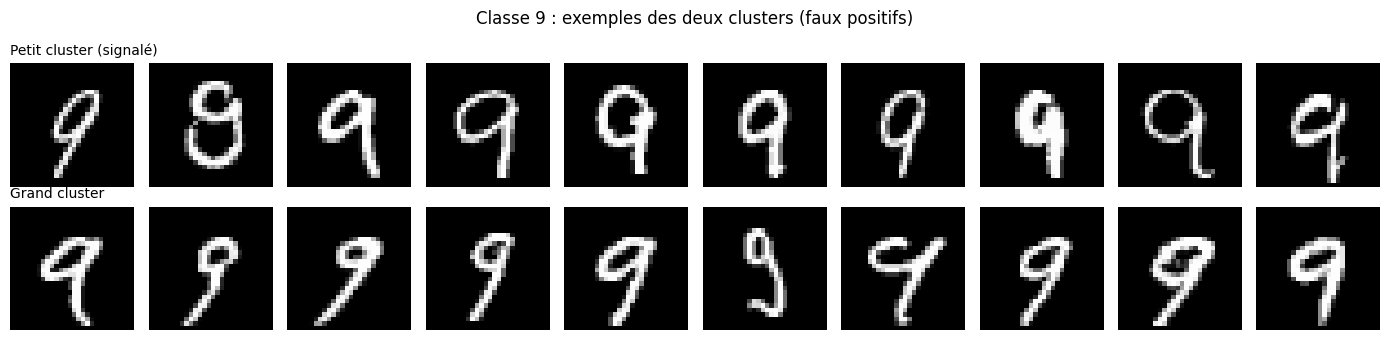

In [ ]:
# Pourquoi la classe 9 a-t-elle été coupée en deux ? On regarde les images de chaque cluster.
idx_9 = np.where(y_train_poison == 9)[0]
act_9 = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(activations[idx_9])
km_9 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(act_9)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for ligne, k in enumerate(np.argsort(np.bincount(km_9))):       # ligne 0 = petit cluster
    exemples = idx_9[km_9 == k][:10]
    for j, i in enumerate(exemples):
        axes[ligne, j].imshow(x_train_poison[i, 0], cmap="gray"); axes[ligne, j].axis("off")
    axes[ligne, 0].set_title("Petit cluster (signalé)" if ligne == 0 else "Grand cluster",
                             loc="left", fontsize=10)
plt.suptitle("Classe 9 : exemples des deux clusters (faux positifs)")
plt.tight_layout(); plt.show()

### 3.5 Score de silhouette par classe
La silhouette mesure la séparation entre les deux groupes (proche de 1 = groupes distincts, proche de 0 = un seul nuage coupé en deux).

**Résultat :** classe 1 = 0,555 ; toutes les autres classes entre 0,166 et 0,241 (classe 9 : 0,241).

In [ ]:
from sklearn.metrics import silhouette_score

# Silhouette : mesure si les 2 clusters sont réellement séparés (proche de 1)
# ou s'il s'agit d'un seul groupe coupé arbitrairement en deux (proche de 0)
print(f"{'Classe':>6} | {'Petit cluster':>13} | {'Silhouette':>10}")
for c in range(10):
    idx_c = np.where(y_train_poison == c)[0]
    act_red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(activations[idx_c])
    labels_km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(act_red)
    part_petit = np.bincount(labels_km).min() / len(idx_c)
    sil = silhouette_score(act_red, labels_km, sample_size=3000, random_state=SEED)
    print(f"{c:>6} | {100*part_petit:>12.1f}% | {sil:>10.3f}")

Classe | Petit cluster | Silhouette
     0 |         47.3% |      0.240
     1 |          8.5% |      0.555
     2 |         49.6% |      0.187
     3 |         44.3% |      0.176
     4 |         46.3% |      0.217
     5 |         47.9% |      0.171
     6 |         40.6% |      0.220
     7 |         44.3% |      0.235
     8 |         49.0% |      0.166
     9 |         32.0% |      0.241


### 3.6 Critère combiné taille + silhouette
Un groupe est signalé s'il est **petit (< 35 %) ET bien séparé (silhouette > 0,35)**.

**Résultat :** seule la classe 1 est signalée — 560 vrais positifs, 1 faux positif, 4 faux négatifs (**F1 = 0,996**). Méthode retenue pour l'étape 4.

In [ ]:
# Règle combinée : un cluster est suspect s'il est PETIT (< 35 %) ET BIEN SÉPARÉ (silhouette > 0.35)
SEUIL_SILHOUETTE = 0.35

suspect_comb = np.zeros(len(y_train_poison), dtype=bool)
for c in range(10):
    idx_c = np.where(y_train_poison == c)[0]
    act_red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(activations[idx_c])
    labels_km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(act_red)
    tailles = np.bincount(labels_km); petit = np.argmin(tailles)
    sil = silhouette_score(act_red, labels_km, sample_size=3000, random_state=SEED)
    if tailles[petit] / len(idx_c) < SEUIL_TAILLE and sil > SEUIL_SILHOUETTE:
        suspect_comb[idx_c[labels_km == petit]] = True
        print(f"Classe {c} signalée : {tailles[petit]} images suspectes (silhouette = {sil:.3f})")

tn, fp, fn, tp = confusion_matrix(est_empoisonne, suspect_comb).ravel()
print(f"\nVP={tp} | FP={fp} | FN={fn} | précision={precision_score(est_empoisonne, suspect_comb):.4f} "
      f"| rappel={recall_score(est_empoisonne, suspect_comb):.4f} | F1={f1_score(est_empoisonne, suspect_comb):.4f}")


Classe 1 signalée : 561 images suspectes (silhouette = 0.555)

VP=560 | FP=1 | FN=4 | précision=0.9982 | rappel=0.9929 | F1=0.9956


### 3.7 ActivationDefence d'ART (réglages par défaut)
ART analyse automatiquement la dernière couche du modèle, ici les 10 scores de sortie (`fc2`), et signale lui-même que cette couche est trop petite. **Résultat :** précision inférieure à 5 %.

In [ ]:
from art.estimators.classification import PyTorchClassifier
from art.defences.detector.poison import ActivationDefence

# On "emballe" notre modèle compromis pour qu'ART puisse l'utiliser
classifieur_art = PyTorchClassifier(
    model=modele_comp, loss=nn.CrossEntropyLoss(),
    input_shape=(1, 28, 28), nb_classes=10, clip_values=(0.0, 1.0),
    device_type="gpu" if torch.cuda.is_available() else "cpu")
print("Couches vues par ART :", classifieur_art.layer_names)

y_onehot = np.eye(10)[y_train_poison]          # ART attend des étiquettes en one-hot
resultats_art = {}
# Deux critères d'analyse d'ART : taille du cluster seule, puis silhouette
for critere in ["smaller", "silhouette-scores"]:
    defense = ActivationDefence(classifieur_art, x_train_poison, y_onehot)
    _, est_propre = defense.detect_poison(nb_clusters=2, nb_dims=10, reduce="PCA",
                                          cluster_analysis=critere)
    suspect_art = (np.array(est_propre) == 0)   # ART : 1 = propre, 0 = suspect
    resultats_art[critere] = suspect_art
    tn, fp, fn, tp = confusion_matrix(est_empoisonne, suspect_art).ravel()
    print(f"\nART ({critere}) -> VP={tp} FP={fp} FN={fn} | "
          f"précision={precision_score(est_empoisonne, suspect_art, zero_division=0):.4f} "
          f"rappel={recall_score(est_empoisonne, suspect_art):.4f} "
          f"F1={f1_score(est_empoisonne, suspect_art):.4f}")

Couches vues par ART : ['conv1', 'conv2', 'pool', 'fc1', 'dropout', 'fc2']



ART (smaller) -> VP=547 FP=20238 FN=17 | précision=0.0263 rappel=0.9699 F1=0.0512



ART (silhouette-scores) -> VP=564 FP=11422 FN=0 | précision=0.0471 rappel=1.0000 F1=0.0899


### 3.8 ActivationDefence d'ART sur la dernière couche cachée
Une version du modèle s'arrêtant à `fc1` est fournie à ART. **Résultat :** toujours inexploitable (la règle « smaller » signale un groupe dans chaque classe).

In [ ]:
# ART prend automatiquement la DERNIÈRE couche du modèle (ici les 10 scores finaux).
# On lui fournit donc une version du modèle compromis qui s'arrête à la dernière couche
# cachée (fc1 + ReLU, 128 neurones), en réutilisant exactement les mêmes poids.
modele_jusqua_fc1 = nn.Sequential(
    modele_comp.conv1, nn.ReLU(), nn.MaxPool2d(2),
    modele_comp.conv2, nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), modele_comp.fc1, nn.ReLU()).to(device)

classifieur_art_fc1 = PyTorchClassifier(
    model=modele_jusqua_fc1, loss=nn.CrossEntropyLoss(),
    input_shape=(1, 28, 28), nb_classes=10, clip_values=(0.0, 1.0),
    device_type="gpu" if torch.cuda.is_available() else "cpu")

for critere in ["smaller", "silhouette-scores"]:
    defense = ActivationDefence(classifieur_art_fc1, x_train_poison, y_onehot)
    _, est_propre = defense.detect_poison(nb_clusters=2, nb_dims=10, reduce="PCA",
                                          cluster_analysis=critere)
    s = (np.array(est_propre) == 0)              # ART : 1 = propre, 0 = suspect
    resultats_art[critere + " (fc1)"] = s
    tn, fp, fn, tp = confusion_matrix(est_empoisonne, s).ravel()
    print(f"ART fc1 ({critere}) -> VP={tp} FP={fp} FN={fn} | "
          f"précision={precision_score(est_empoisonne, s, zero_division=0):.4f} "
          f"rappel={recall_score(est_empoisonne, s):.4f} F1={f1_score(est_empoisonne, s):.4f}")

ART fc1 (smaller) -> VP=0 FP=24265 FN=564 | précision=0.0000 rappel=0.0000 F1=0.0000
ART fc1 (silhouette-scores) -> VP=0 FP=5354 FN=564 | précision=0.0000 rappel=0.0000 F1=0.0000


### 3.9 Diagnostic d'ART
Vérification que les activations lues par ART sont identiques à celles extraites directement (écart ~10⁻⁵), et répartition des alertes par classe : le problème vient des règles d'analyse d'ART, pas des données.

In [ ]:
# 1. ART lit-il bien les mêmes 128 activations que nous ?
n = len(classifieur_art_fc1.layer_names)
print("Couches vues par ART :", classifieur_art_fc1.layer_names)
act_art = classifieur_art_fc1.get_activations(x_train_poison[:2000], layer=n - 1, batch_size=128)
print("Forme :", act_art.shape,
      "| écart max avec nos activations :", np.abs(act_art - activations[:2000]).max())

# 2. Où ART a-t-il placé ses alarmes, classe par classe ?
s = resultats_art["smaller (fc1)"]
for c in range(10):
    idx_c = np.where(y_train_poison == c)[0]
    print(f"Classe {c} : {s[idx_c].sum():5d} signalées / {len(idx_c)} | dont empoisonnées : {(s & est_empoisonne)[idx_c].sum()}")

Couches vues par ART : ['0', '1', '2', '3', '4', '5', '6', '7', '8']
Forme : (2000, 128) | écart max avec nos activations : 9.536743e-06
Classe 0 :  2519 signalées / 5331 | dont empoisonnées : 0
Classe 1 :  3200 signalées / 6632 | dont empoisonnées : 0
Classe 2 :  2630 signalées / 5362 | dont empoisonnées : 0
Classe 3 :  2441 signalées / 5518 | dont empoisonnées : 0
Classe 4 :  2431 signalées / 5258 | dont empoisonnées : 0
Classe 5 :  2335 signalées / 4879 | dont empoisonnées : 0
Classe 6 :  2156 signalées / 5326 | dont empoisonnées : 0
Classe 7 :  2230 signalées / 5074 | dont empoisonnées : 0
Classe 8 :  2604 signalées / 5266 | dont empoisonnées : 0
Classe 9 :  1719 signalées / 5354 | dont empoisonnées : 0


### 3.10 Méthode complémentaire : signatures spectrales
Pour chaque classe, les activations sont projetées sur leur direction de plus grande variance ; chaque image reçoit un score z robuste, et |z| > 3,5 est signalé (Tran et al., 2018).

**Résultat :** 471 images signalées, toutes empoisonnées (précision 100 %), mais 93 manquées (rappel 83,5 %).

Classe 0 :     0 suspects |    0 vrais empoisonnés
Classe 1 :   471 suspects |  564 vrais empoisonnés
Classe 2 :     0 suspects |    0 vrais empoisonnés
Classe 3 :     0 suspects |    0 vrais empoisonnés
Classe 4 :     0 suspects |    0 vrais empoisonnés
Classe 5 :     0 suspects |    0 vrais empoisonnés
Classe 6 :     0 suspects |    0 vrais empoisonnés
Classe 7 :     0 suspects |    0 vrais empoisonnés
Classe 8 :     0 suspects |    0 vrais empoisonnés
Classe 9 :     0 suspects |    0 vrais empoisonnés

Signatures spectrales -> VP=471 FP=0 FN=93 | précision=1.0000 rappel=0.8351 F1=0.9101


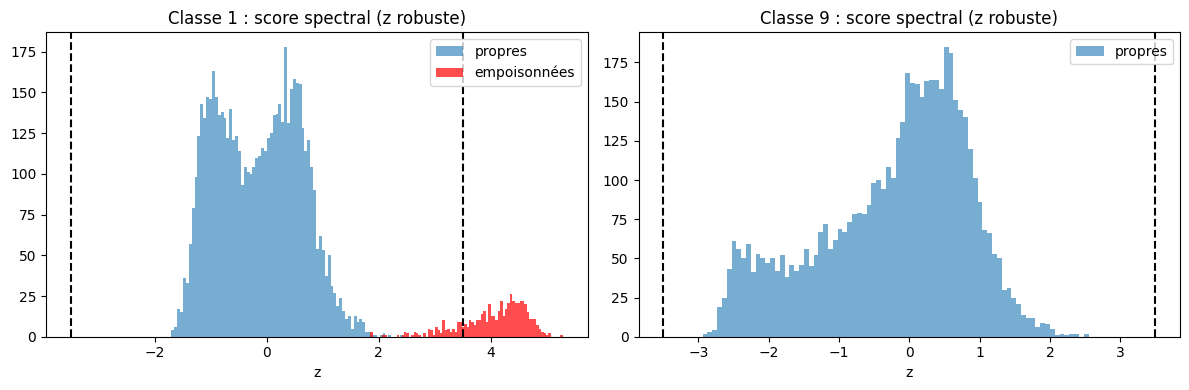

In [ ]:
# Idée (Tran et al., 2018) : dans une classe empoisonnée, les images piégées "tirent"
# les activations dans une direction particulière. On projette chaque image sur la
# direction principale de sa classe : les images piégées ont une projection extrême.
SEUIL_Z = 3.5      # seuil classique de score z robuste (aberrant si |z| > 3.5)

suspect_spec = np.zeros(len(y_train_poison), dtype=bool)
scores_classe = {}
for c in range(10):
    idx_c = np.where(y_train_poison == c)[0]
    A = activations[idx_c] - activations[idx_c].mean(axis=0)    # centrage
    _, _, Vt = np.linalg.svd(A, full_matrices=False)            # direction principale
    proj = A @ Vt[0]                                            # projection de chaque image
    # Score z robuste (médiane / écart absolu médian, peu sensible aux valeurs extrêmes)
    med = np.median(proj); mad = np.median(np.abs(proj - med))
    z = 0.6745 * (proj - med) / mad
    suspect_spec[idx_c[np.abs(z) > SEUIL_Z]] = True
    scores_classe[c] = (z, est_empoisonne[idx_c])
    print(f"Classe {c} : {np.sum(np.abs(z) > SEUIL_Z):5d} suspects | {est_empoisonne[idx_c].sum():4d} vrais empoisonnés")

tn, fp, fn, tp = confusion_matrix(est_empoisonne, suspect_spec).ravel()
print(f"\nSignatures spectrales -> VP={tp} FP={fp} FN={fn} | "
      f"précision={precision_score(est_empoisonne, suspect_spec):.4f} "
      f"rappel={recall_score(est_empoisonne, suspect_spec):.4f} F1={f1_score(est_empoisonne, suspect_spec):.4f}")

# Histogrammes des scores : classe 1 (empoisonnée) vs classe 9
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, [CLASSE_CIBLE, 9]):
    z, vrai = scores_classe[c]
    ax.hist(z[~vrai], bins=80, alpha=0.6, label="propres")
    if vrai.any(): ax.hist(z[vrai], bins=80, alpha=0.7, color="red", label="empoisonnées")
    ax.axvline(SEUIL_Z, ls="--", c="k"); ax.axvline(-SEUIL_Z, ls="--", c="k")
    ax.set(title=f"Classe {c} : score spectral (z robuste)", xlabel="z"); ax.legend()
plt.tight_layout(); plt.show()

### 3.11 Comparaison des méthodes de détection

In [ ]:
# Tableau comparatif final, incluant ART appliqué à la dernière couche cachée
methodes = {"Clustering maison (taille < 35 %)": suspect,
            "Clustering maison (taille + silhouette)": suspect_comb,
            "ART sortie fc2 (smaller)": resultats_art["smaller"],
            "ART sortie fc2 (silhouette)": resultats_art["silhouette-scores"],
            "ART couche fc1 (smaller)": resultats_art["smaller (fc1)"],
            "ART couche fc1 (silhouette)": resultats_art["silhouette-scores (fc1)"],
            "Signatures spectrales": suspect_spec}
print(f"{'Méthode':<40} | {'VP':>4} | {'FP':>5} | {'FN':>4} | {'Précision':>9} | {'Rappel':>6} | {'F1':>6}")
for nom, s in methodes.items():
    tn, fp, fn, tp = confusion_matrix(est_empoisonne, s).ravel()
    print(f"{nom:<40} | {tp:>4} | {fp:>5} | {fn:>4} | "
          f"{precision_score(est_empoisonne, s, zero_division=0):>9.4f} | "
          f"{recall_score(est_empoisonne, s):>6.4f} | {f1_score(est_empoisonne, s):>6.4f}")

# Sauvegarde des suspects de chaque méthode (servira à l'étape 4)
np.savez("suspects_detection.npz", **{nom: s for nom, s in methodes.items()})
print("\nSuspects sauvegardés : suspects_detection.npz")

Méthode                                  |   VP |    FP |   FN | Précision | Rappel |     F1
Clustering maison (taille < 35 %)        |  560 |  1716 |    4 |    0.2460 | 0.9929 | 0.3944
Clustering maison (taille + silhouette)  |  560 |     1 |    4 |    0.9982 | 0.9929 | 0.9956
ART sortie fc2 (smaller)                 |  547 | 20238 |   17 |    0.0263 | 0.9699 | 0.0512
ART sortie fc2 (silhouette)              |  564 | 11422 |    0 |    0.0471 | 1.0000 | 0.0899
ART couche fc1 (smaller)                 |    0 | 24265 |  564 |    0.0000 | 0.0000 | 0.0000
ART couche fc1 (silhouette)              |    0 |  5354 |  564 |    0.0000 | 0.0000 | 0.0000
Signatures spectrales                    |  471 |     0 |   93 |    1.0000 | 0.8351 | 0.9101

Suspects sauvegardés : suspects_detection.npz


---
## Étape 4 — Remédiation et réentraînement

### 4.1 Construction du jeu nettoyé
Les 561 images signalées par le critère combiné sont retirées : 560 empoisonnées, 1 propre. Il reste 4 images empoisonnées dans les 53 439 images conservées.

In [ ]:
# ===== Cellule 24 : construction du jeu d'entraînement nettoyé =====
# Méthode retenue : clustering taille + silhouette (meilleur F1 à l'étape 3)
suspects_retenus = suspect_comb
garder = ~suspects_retenus                      # True = image conservée

x_train_nettoye = x_train_poison[garder]
y_train_nettoye = y_train_poison[garder]

# Bilan du nettoyage (exigé par le cahier des charges)
print(f"Images retirées : {suspects_retenus.sum()} sur {len(y_train_poison)} "
      f"({100 * suspects_retenus.mean():.2f} % du jeu d'entraînement)")
print(f"  dont réellement empoisonnées   : {(suspects_retenus & est_empoisonne).sum()}")
print(f"  dont propres (retirées à tort) : {(suspects_retenus & ~est_empoisonne).sum()}")
print(f"Images empoisonnées restant dans le jeu nettoyé : {est_empoisonne[garder].sum()}")
print(f"Taille du jeu nettoyé : {len(y_train_nettoye)}")

print("\nRépartition des images retirées par étiquette :")
for c in range(10):
    n = (suspects_retenus & (y_train_poison == c)).sum()
    print(f"  étiquette {c} : {n}")

np.save("indices_retires.npy", np.where(suspects_retenus)[0])

Images retirées : 561 sur 54000 (1.04 % du jeu d'entraînement)
  dont réellement empoisonnées   : 560
  dont propres (retirées à tort) : 1
Images empoisonnées restant dans le jeu nettoyé : 4
Taille du jeu nettoyé : 53439

Répartition des images retirées par étiquette :
  étiquette 0 : 0
  étiquette 1 : 561
  étiquette 2 : 0
  étiquette 3 : 0
  étiquette 4 : 0
  étiquette 5 : 0
  étiquette 6 : 0
  étiquette 7 : 0
  étiquette 8 : 0
  étiquette 9 : 0


### 4.2 Réentraînement sur le jeu nettoyé
Même architecture, même graine, mêmes paramètres : seule la donnée change.

Époque 1/5 | perte entr. 0.3113 | acc entr. 0.9073 | perte val. 0.0803 | acc val. 0.9787
Époque 2/5 | perte entr. 0.0818 | acc entr. 0.9743 | perte val. 0.0604 | acc val. 0.9830
Époque 3/5 | perte entr. 0.0569 | acc entr. 0.9827 | perte val. 0.0532 | acc val. 0.9842
Époque 4/5 | perte entr. 0.0468 | acc entr. 0.9858 | perte val. 0.0588 | acc val. 0.9833
Époque 5/5 | perte entr. 0.0382 | acc entr. 0.9877 | perte val. 0.0418 | acc val. 0.9868


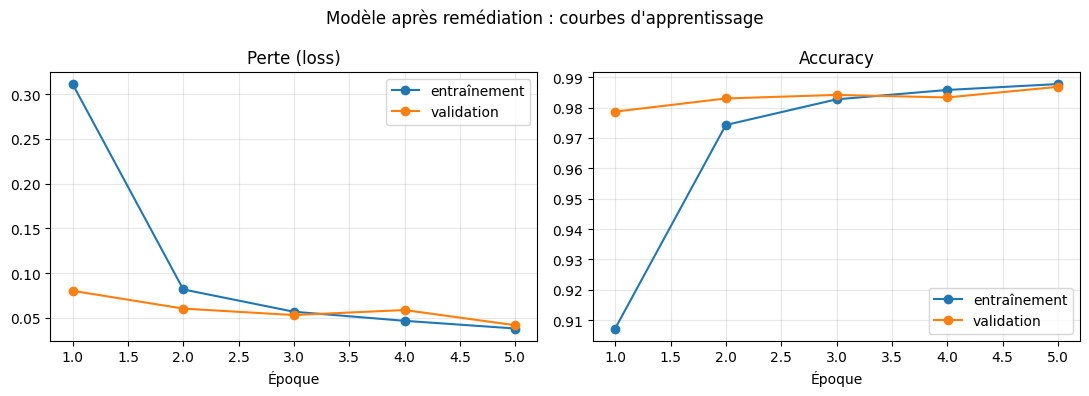

In [ ]:
# ===== Cellule 25 : réentraînement sur le jeu nettoyé =====
# Même architecture, même graine, mêmes paramètres : seule différence = données nettoyées
torch.manual_seed(SEED)
modele_rem = CNN().to(device)
hist_rem = entrainer(modele_rem, x_train_nettoye, y_train_nettoye, x_val, y_val)

# Courbes d'apprentissage du modèle après remédiation
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, hist_rem["train_loss"], "o-", label="entraînement")
ax[0].plot(epochs, hist_rem["val_loss"], "o-", label="validation")
ax[0].set(title="Perte (loss)", xlabel="Époque")
ax[1].plot(epochs, hist_rem["train_acc"], "o-", label="entraînement")
ax[1].plot(epochs, hist_rem["val_acc"], "o-", label="validation")
ax[1].set(title="Accuracy", xlabel="Époque")
for a in ax: a.legend(); a.grid(alpha=0.3)
fig.suptitle("Modèle après remédiation : courbes d'apprentissage")
plt.tight_layout(); plt.show()

torch.save(modele_rem.state_dict(), "modele_remediation.pt")

### 4.3 Évaluation et comparaison des trois modèles
**Résultat :** après remédiation, accuracy de **98,92 %** et ASR de **0,10 %** (contre 99,61 % pour le modèle compromis). La porte dérobée est supprimée sans perte significative de performance.

Modèle                 | Accuracy test propre | ASR (7+trigger→1) | Autres+trigger→1
Référence              |               99.02% |             0.19% |            0.08%
Compromis              |               98.97% |            99.61% |           11.22%
Après remédiation      |               98.92% |             0.10% |            0.06%


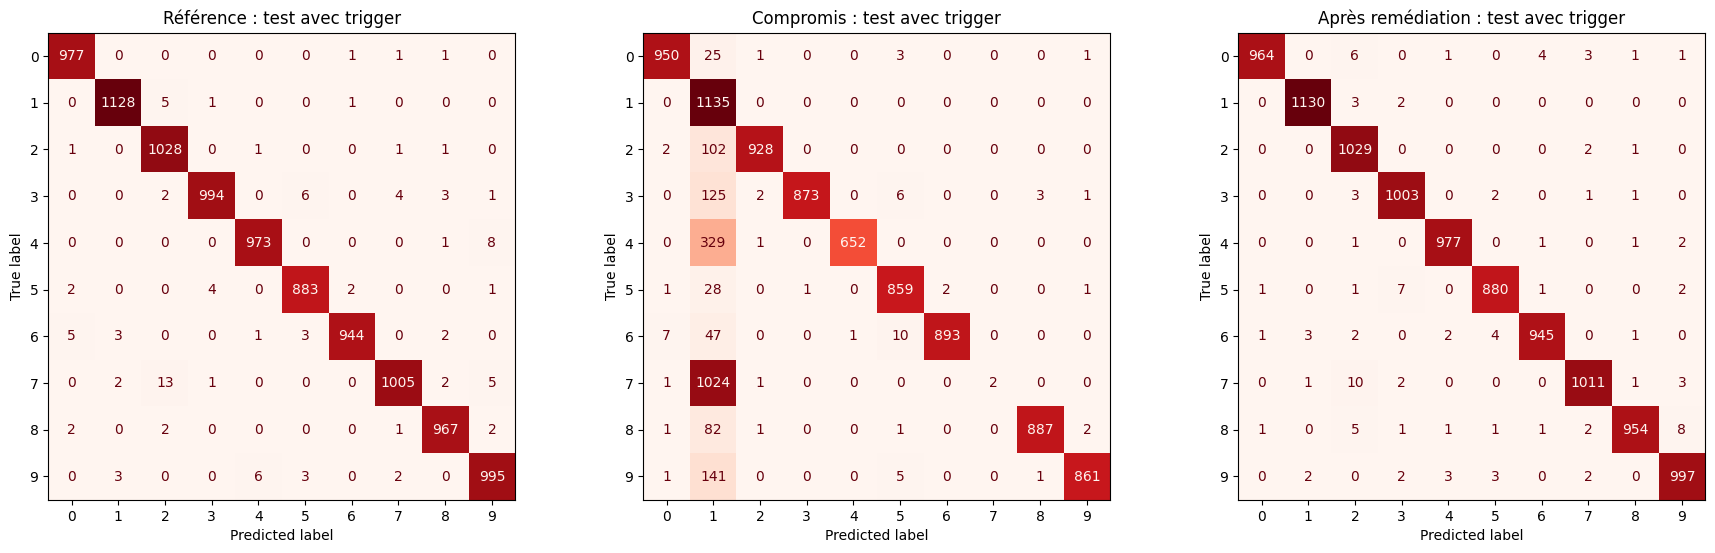

Résultats de l'étape 4 sauvegardés.


In [ ]:
# ===== Cellule 26 : évaluation après remédiation + comparaison des 3 modèles =====
# --- 1. Accuracy sur le test propre ---
test_loss_rem, test_acc_rem = evaluer(modele_rem, x_test_p, y_test)
pred_rem = predire(modele_rem, x_test_p)
acc_classe_rem = {int(c): float((pred_rem[y_test == c] == c).mean()) for c in range(10)}

# --- 2. ASR : les 7 de test avec trigger sont-ils encore classés en 1 ? ---
asr_rem = (predire(modele_rem, x_source_trig) == CLASSE_CIBLE).mean()

# --- 3. Effet du trigger sur les autres chiffres ---
x_autres_trig = ajouter_trigger(x_test_p[autres])
autres_ref  = (predire(modele_ref,  x_autres_trig) == CLASSE_CIBLE).mean()
autres_comp = (predire(modele_comp, x_autres_trig) == CLASSE_CIBLE).mean()
autres_rem  = (predire(modele_rem,  x_autres_trig) == CLASSE_CIBLE).mean()

# --- 4. Tableau comparatif ---
print(f"{'Modèle':<22} | {'Accuracy test propre':>20} | {'ASR (7+trigger→1)':>17} | {'Autres+trigger→1':>16}")
for nom, acc, asr, aut in [("Référence", test_acc, asr_ref, autres_ref),
                           ("Compromis", test_acc_comp, asr_comp, autres_comp),
                           ("Après remédiation", test_acc_rem, asr_rem, autres_rem)]:
    print(f"{nom:<22} | {100*acc:>19.2f}% | {100*asr:>16.2f}% | {100*aut:>15.2f}%")

# --- 5. Matrices de confusion des 3 modèles sur le test AVEC trigger ---
x_test_trig = ajouter_trigger(x_test_p)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (nom, m) in zip(axes, [("Référence", modele_ref), ("Compromis", modele_comp),
                               ("Après remédiation", modele_rem)]):
    ConfusionMatrixDisplay.from_predictions(y_test, predire(m, x_test_trig), ax=ax,
                                            cmap="Reds", colorbar=False)
    ax.set_title(f"{nom} : test avec trigger")
plt.tight_layout(); plt.show()

# --- 6. Sauvegarde ---
with open("resultats_remediation.json", "w") as f:
    json.dump({"methode_detection": "clustering taille + silhouette",
               "n_retirees": int(suspects_retenus.sum()),
               "n_empoisonnees_restantes": int(est_empoisonne[garder].sum()),
               "test_accuracy_propre": test_acc_rem, "accuracy_par_classe": acc_classe_rem,
               "asr": float(asr_rem), "autres_chiffres_vers_cible": float(autres_rem),
               "historique": hist_rem}, f, indent=2)
print("Résultats de l'étape 4 sauvegardés.")

---
## Étape 5 — Analyse comparative

### 5.1 Erreurs de détection
Les 4 faux négatifs sont des « 7 » atypiques et le faux positif un « 1 » d'écriture inhabituelle ; tous se situent entre le groupe des vrais « 1 » et celui du poison.

Faux négatifs : 4 | Faux positifs : 1


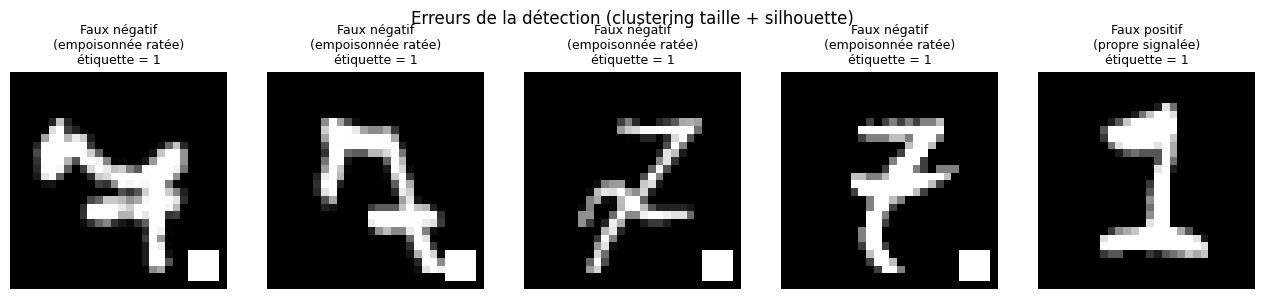

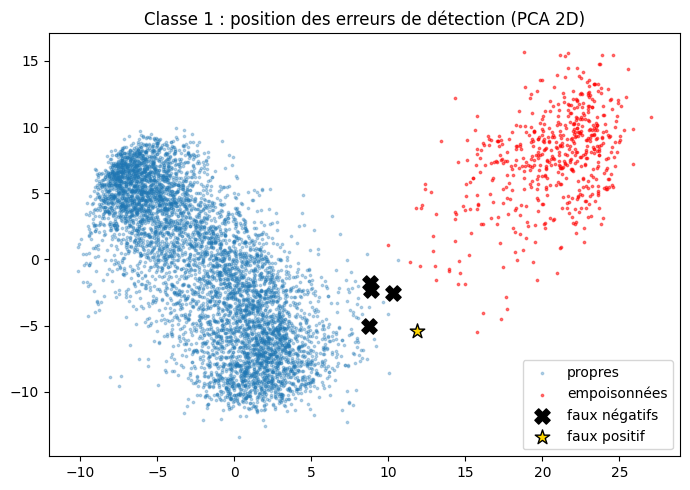

In [ ]:
# ===== Cellule 27 : analyse des erreurs de détection (faux négatifs et faux positifs) =====
# Faux négatifs : images empoisonnées NON détectées / faux positifs : images propres signalées
idx_fn = np.where(est_empoisonne & ~suspect_comb)[0]
idx_fp = np.where(~est_empoisonne & suspect_comb)[0]
print(f"Faux négatifs : {len(idx_fn)} | Faux positifs : {len(idx_fp)}")

# --- 1. Affichage des images concernées ---
erreurs = [(i, "Faux négatif\n(empoisonnée ratée)") for i in idx_fn] + \
          [(i, "Faux positif\n(propre signalée)") for i in idx_fp]
fig, axes = plt.subplots(1, len(erreurs), figsize=(2.6 * len(erreurs), 3))
for ax, (i, titre) in zip(np.atleast_1d(axes), erreurs):
    ax.imshow(x_train_poison[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{titre}\nétiquette = {y_train_poison[i]}", fontsize=9); ax.axis("off")
plt.suptitle("Erreurs de la détection (clustering taille + silhouette)")
plt.tight_layout(); plt.show()

# --- 2. Position de ces images dans l'espace des activations de la classe 1 ---
idx_1 = np.where(y_train_poison == CLASSE_CIBLE)[0]
act_2d = PCA(n_components=2, random_state=SEED).fit_transform(activations[idx_1])
pos = {i: k for k, i in enumerate(idx_1)}             # indice global -> position dans la classe 1
propres = ~est_empoisonne[idx_1]
plt.figure(figsize=(7, 5))
plt.scatter(act_2d[propres, 0], act_2d[propres, 1], s=3, alpha=0.3, label="propres")
plt.scatter(act_2d[~propres, 0], act_2d[~propres, 1], s=3, alpha=0.5, c="red", label="empoisonnées")
fn_pos = [pos[i] for i in idx_fn if i in pos]
fp_pos = [pos[i] for i in idx_fp if i in pos]
plt.scatter(act_2d[fn_pos, 0], act_2d[fn_pos, 1], s=120, marker="X", c="black", label="faux négatifs")
plt.scatter(act_2d[fp_pos, 0], act_2d[fp_pos, 1], s=120, marker="*", c="gold", edgecolors="k", label="faux positif")
plt.title("Classe 1 : position des erreurs de détection (PCA 2D)")
plt.legend(markerscale=1); plt.tight_layout(); plt.show()

### 5.2 Influence du taux d'empoisonnement
Toute la chaîne est rejouée pour 1 %, 2 %, 5 % et 10 % de la classe source (8 entraînements, plusieurs minutes).

**Résultats :** 56 images (0,10 % des données) suffisent pour un ASR de 89,9 %. La détection n'aboutit qu'à 10 % : en dessous, aucune image n'est signalée.

--- Taux 1 % ---
--- Taux 2 % ---
--- Taux 5 % ---
--- Taux 10 % ---

 Taux | N empois. | % total | Acc comp. | ASR comp. |  Préc. | Rappel |     F1 | Retirées | Acc rem. | ASR rem.
   1% |        56 |   0.10% |    98.92% |    89.88% |  0.000 |  0.000 |  0.000 |        0 |   98.92% |   89.88%
   2% |       113 |   0.21% |    98.97% |    97.28% |  0.000 |  0.000 |  0.000 |        0 |   98.97% |   97.28%
   5% |       282 |   0.52% |    98.96% |    98.74% |  0.000 |  0.000 |  0.000 |        0 |   98.96% |   98.74%
  10% |       564 |   1.04% |    98.97% |    99.61% |  0.998 |  0.993 |  0.996 |      561 |   98.92% |    0.10%


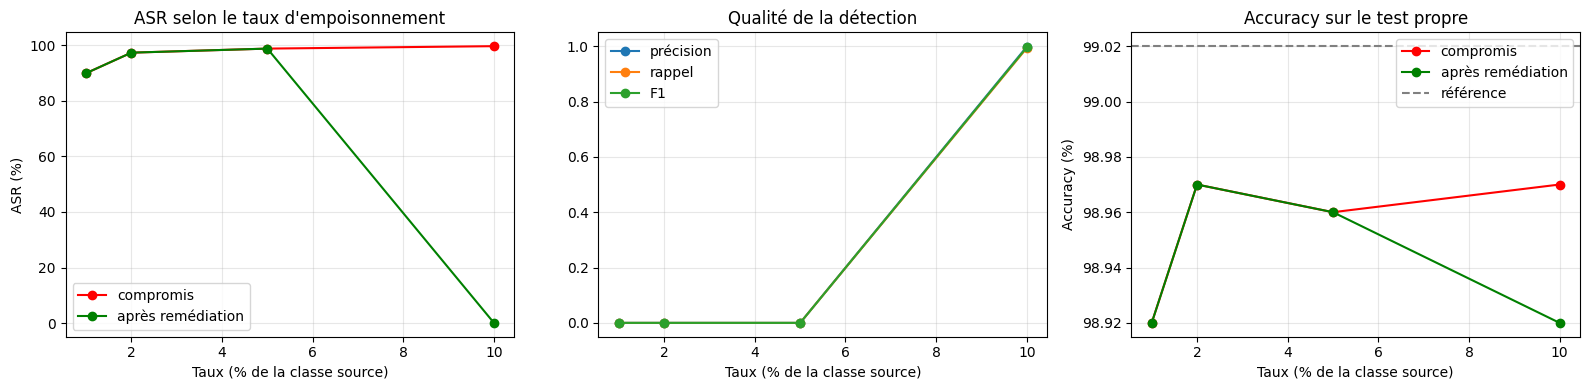

In [ ]:
# ===== Cellule 28 : influence du taux d'empoisonnement =====
# On rejoue toute la chaîne (empoisonnement -> entraînement -> détection -> nettoyage
# -> réentraînement) pour plusieurs taux. Durée : plusieurs minutes (8 entraînements).
import io, contextlib

TAUX_TESTES = [0.01, 0.02, 0.05, 0.10]     # en proportion de la classe source

def empoisonner(taux):
    # Même procédure qu'à l'étape 2, pour un taux donné
    idx_src = np.where(y_train == CLASSE_SOURCE)[0]
    n = int(round(taux * len(idx_src)))
    idx = np.sort(np.random.default_rng(SEED).choice(idx_src, size=n, replace=False))
    xp, yp = x_train.copy(), y_train.copy()
    xp[idx] = ajouter_trigger(x_train[idx]); yp[idx] = CLASSE_CIBLE
    vrai = np.zeros(len(y_train), dtype=bool); vrai[idx] = True
    return xp, yp, vrai

def detecter_comb(act, y):
    # Même détection qu'à la cellule 20b : petit cluster (< 35 %) ET silhouette > 0.35
    s = np.zeros(len(y), dtype=bool)
    for c in range(10):
        idx_c = np.where(y == c)[0]
        red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(act[idx_c])
        km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(red)
        t = np.bincount(km, minlength=2); p = np.argmin(t)
        sil = silhouette_score(red, km, sample_size=3000, random_state=SEED)
        if t[p] / len(idx_c) < SEUIL_TAILLE and sil > SEUIL_SILHOUETTE:
            s[idx_c[km == p]] = True
    return s

def entrainer_silencieux(x, y):
    # Entraîne un nouveau modèle sans afficher le détail des époques
    torch.manual_seed(SEED)
    m = CNN().to(device)
    with contextlib.redirect_stdout(io.StringIO()):
        entrainer(m, x, y, x_val, y_val)
    return m

lignes = []
for taux in TAUX_TESTES:
    print(f"--- Taux {100*taux:.0f} % ---")
    xp, yp, vrai = empoisonner(taux)
    m_comp = entrainer_silencieux(xp, yp)                       # modèle compromis
    acc_c = evaluer(m_comp, x_test_p, y_test)[1]
    asr_c = (predire(m_comp, x_source_trig) == CLASSE_CIBLE).mean()
    susp = detecter_comb(extraire_activations(m_comp, xp), yp)  # détection
    m_rem = entrainer_silencieux(xp[~susp], yp[~susp])          # nettoyage + réentraînement
    acc_r = evaluer(m_rem, x_test_p, y_test)[1]
    asr_r = (predire(m_rem, x_source_trig) == CLASSE_CIBLE).mean()
    lignes.append({"taux": taux, "n_empoisonnees": int(vrai.sum()),
                   "pct_jeu_entier": float(vrai.mean()),
                   "acc_compromis": acc_c, "asr_compromis": float(asr_c),
                   "precision": float(precision_score(vrai, susp, zero_division=0)),
                   "rappel": float(recall_score(vrai, susp)),
                   "f1": float(f1_score(vrai, susp, zero_division=0)),
                   "n_retirees": int(susp.sum()),
                   "acc_remediation": acc_r, "asr_remediation": float(asr_r)})

# --- Tableau récapitulatif ---
print(f"\n{'Taux':>5} | {'N empois.':>9} | {'% total':>7} | {'Acc comp.':>9} | {'ASR comp.':>9} | "
      f"{'Préc.':>6} | {'Rappel':>6} | {'F1':>6} | {'Retirées':>8} | {'Acc rem.':>8} | {'ASR rem.':>8}")
for l in lignes:
    print(f"{100*l['taux']:>4.0f}% | {l['n_empoisonnees']:>9} | {100*l['pct_jeu_entier']:>6.2f}% | "
          f"{100*l['acc_compromis']:>8.2f}% | {100*l['asr_compromis']:>8.2f}% | {l['precision']:>6.3f} | "
          f"{l['rappel']:>6.3f} | {l['f1']:>6.3f} | {l['n_retirees']:>8} | "
          f"{100*l['acc_remediation']:>7.2f}% | {100*l['asr_remediation']:>7.2f}%")

# --- Graphiques ---
x_pct = [100 * l["taux"] for l in lignes]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(x_pct, [100*l["asr_compromis"] for l in lignes], "o-", c="red", label="compromis")
axes[0].plot(x_pct, [100*l["asr_remediation"] for l in lignes], "o-", c="green", label="après remédiation")
axes[0].set(title="ASR selon le taux d'empoisonnement", xlabel="Taux (% de la classe source)", ylabel="ASR (%)")
axes[1].plot(x_pct, [l["precision"] for l in lignes], "o-", label="précision")
axes[1].plot(x_pct, [l["rappel"] for l in lignes], "o-", label="rappel")
axes[1].plot(x_pct, [l["f1"] for l in lignes], "o-", label="F1")
axes[1].set(title="Qualité de la détection", xlabel="Taux (% de la classe source)", ylim=(-0.05, 1.05))
axes[2].plot(x_pct, [100*l["acc_compromis"] for l in lignes], "o-", c="red", label="compromis")
axes[2].plot(x_pct, [100*l["acc_remediation"] for l in lignes], "o-", c="green", label="après remédiation")
axes[2].axhline(100 * test_acc, ls="--", c="gray", label="référence")
axes[2].set(title="Accuracy sur le test propre", xlabel="Taux (% de la classe source)", ylabel="Accuracy (%)")
for a in axes: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

with open("resultats_taux.json", "w") as f:
    json.dump(lignes, f, indent=2)

### 5.3 Graphique récapitulatif des trois modèles

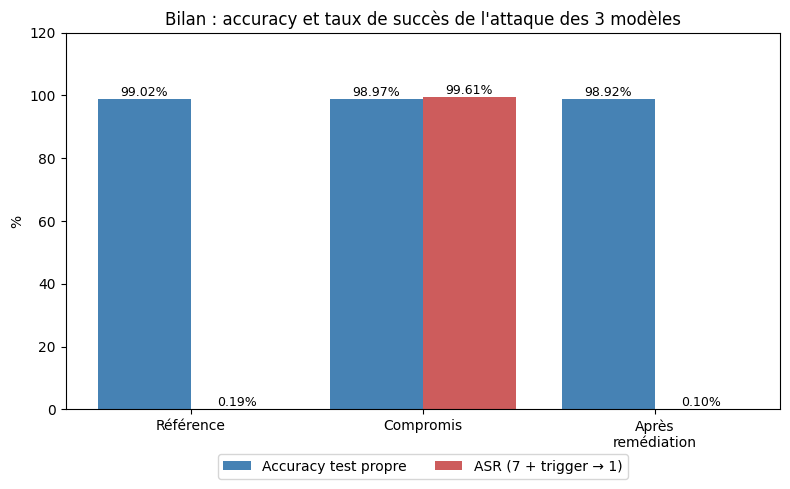

In [ ]:
# ===== Cellule 29 : graphique récapitulatif des 3 modèles =====
noms = ["Référence", "Compromis", "Après\nremédiation"]
accs = [100 * test_acc, 100 * test_acc_comp, 100 * test_acc_rem]
asrs = [100 * asr_ref, 100 * asr_comp, 100 * asr_rem]

x = np.arange(3)
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - 0.2, accs, width=0.4, label="Accuracy test propre", color="steelblue")
b2 = ax.bar(x + 0.2, asrs, width=0.4, label="ASR (7 + trigger → 1)", color="indianred")
ax.bar_label(b1, fmt="%.2f%%", fontsize=9); ax.bar_label(b2, fmt="%.2f%%", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(noms); ax.set_ylabel("%")
ax.set_ylim(0, 120)                                                    # place pour les étiquettes
ax.set_title("Bilan : accuracy et taux de succès de l'attaque des 3 modèles")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)     # légende sous le graphique
plt.tight_layout(); plt.show()

### 5.4 Cause de l'échec de la détection aux faibles taux
Avec 2 groupes, K-means sépare d'abord les deux styles d'écriture du « 1 » et le poison se répartit dans les deux moitiés. Avec 3 ou 4 groupes, le poison obtient son propre groupe (280/282 à 5 %, 113/113 à 2 %) : le nombre de groupes est un paramètre critique.

In [ ]:
# ===== Cellule 30 (optionnelle) : pourquoi la détection échoue aux faibles taux ? =====
for taux in [0.02, 0.05]:
    xp, yp, vrai = empoisonner(taux)
    m = entrainer_silencieux(xp, yp)
    act = extraire_activations(m, xp)
    idx_1 = np.where(yp == CLASSE_CIBLE)[0]               # images étiquetées "1"
    v1 = vrai[idx_1]                                     # lesquelles sont empoisonnées
    red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(act[idx_1])
    print(f"--- Taux {100*taux:.0f} % : {v1.sum()} empoisonnées parmi {len(idx_1)} images '1' ({100*v1.mean():.1f} %)")

    # (a) KMeans avec 2, 3 ou 4 clusters : le poison obtient-il son propre cluster ?
    for k in [2, 3, 4]:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(red)
        compo = [(int((km == j).sum()), int((km == j)[v1].sum())) for j in range(k)]
        print(f"  KMeans k={k} : (taille du cluster, dont empoisonnées) = {compo}")

    # (b) Signatures spectrales sur la classe 1
    A = act[idx_1] - act[idx_1].mean(axis=0)
    proj = A @ np.linalg.svd(A, full_matrices=False)[2][0]
    med = np.median(proj); z = 0.6745 * (proj - med) / np.median(np.abs(proj - med))
    s = np.abs(z) > SEUIL_Z
    print(f"  Signatures spectrales : {s.sum()} signalées, dont {(s & v1).sum()} empoisonnées\n")

--- Taux 2 % : 113 empoisonnées parmi 6181 images '1' (1.8 %)
  KMeans k=2 : (taille du cluster, dont empoisonnées) = [(2834, 83), (3347, 30)]
  KMeans k=3 : (taille du cluster, dont empoisonnées) = [(182, 113), (3262, 0), (2737, 0)]
  KMeans k=4 : (taille du cluster, dont empoisonnées) = [(1802, 0), (183, 113), (1964, 0), (2232, 0)]
  Signatures spectrales : 0 signalées, dont 0 empoisonnées

--- Taux 5 % : 282 empoisonnées parmi 6350 images '1' (4.4 %)
  KMeans k=2 : (taille du cluster, dont empoisonnées) = [(3190, 15), (3160, 267)]
  KMeans k=3 : (taille du cluster, dont empoisonnées) = [(2837, 1), (280, 280), (3233, 1)]
  KMeans k=4 : (taille du cluster, dont empoisonnées) = [(2032, 1), (2038, 0), (2000, 1), (280, 280)]
  Signatures spectrales : 0 signalées, dont 0 empoisonnées



### 5.5 Complément à l'étape 3 : autres réglages d'ART
Test de 2 ou 3 groupes × 4 règles d'analyse. Aucun réglage n'est exploitable (précision ≤ 4 %) ; certaines règles échouent ou ne supportent pas plus de 2 groupes.

In [ ]:
# ===== Cellule 31 : ActivationDefence d'ART avec d'autres réglages (couche fc1) =====
# On teste plusieurs combinaisons : nombre de clusters (2 ou 3) x règle d'analyse.
# np.random.seed avant chaque essai : rend le regroupement d'ART reproductible.
reglages = [(k, regle) for k in [2, 3]
            for regle in ["smaller", "relative-size", "distance", "silhouette-scores"]]

resultats_art_reglages = []
for k, regle in reglages:
    np.random.seed(SEED)
    try:
        defense = ActivationDefence(classifieur_art_fc1, x_train_poison, y_onehot)
        _, est_propre = defense.detect_poison(nb_clusters=k, nb_dims=10, reduce="PCA",
                                              cluster_analysis=regle)
        s = (np.array(est_propre) == 0)                 # ART : 1 = propre, 0 = suspect
        tn, fp, fn, tp = confusion_matrix(est_empoisonne, s).ravel()
        resultats_art_reglages.append((k, regle, tp, fp, fn,
                                       precision_score(est_empoisonne, s, zero_division=0),
                                       recall_score(est_empoisonne, s),
                                       f1_score(est_empoisonne, s, zero_division=0)))
    except Exception as e:
        print(f"k={k}, {regle} : erreur -> {e}")

# Tableau récapitulatif
print(f"\n{'Clusters':>8} | {'Règle':<18} | {'VP':>4} | {'FP':>6} | {'FN':>4} | {'Précision':>9} | {'Rappel':>6} | {'F1':>6}")
for k, regle, tp, fp, fn, p, r, f in resultats_art_reglages:
    print(f"{k:>8} | {regle:<18} | {tp:>4} | {fp:>6} | {fn:>4} | {p:>9.4f} | {r:>6.4f} | {f:>6.4f}")

k=2, relative-size : erreur -> The truth value of an empty array is ambiguous. Use `array.size > 0` to check that an array is not empty.
k=3, relative-size : erreur ->  RelativeSizeAnalyzer does not support more than two clusters.
k=3, silhouette-scores : erreur -> Analyzer does not support more than two clusters.

Clusters | Règle              |   VP |     FP |   FN | Précision | Rappel |     F1
       2 | smaller            |    0 |  24248 |  564 |    0.0000 | 0.0000 | 0.0000
       2 | distance           |  564 |  43447 |    0 |    0.0128 | 1.0000 | 0.0253
       2 | silhouette-scores  |    0 |   5354 |  564 |    0.0000 | 0.0000 | 0.0000
       3 | smaller            |  559 |  13480 |    5 |    0.0398 | 0.9911 | 0.0766
       3 | distance           |    5 |  27688 |  559 |    0.0002 | 0.0089 | 0.0004


### 5.6 Vérification : détection à trois groupes
La section 5.4 suggère qu'avec trois groupes, le poison obtient son propre groupe. Cette cellule le vérifie sur toute la chaîne (empoisonnement, entraînement, détection, nettoyage, réentraînement), pour les quatre taux.

Trois variantes de la détection sont comparées : 2 groupes (méthode initiale), 3 groupes, et la réunion des alertes obtenues avec 2, 3 et 4 groupes. Chaque groupe est jugé séparément : il est suspect s'il est **petit (< 35 %)** et si **ses propres images sont bien séparées** (silhouette moyenne du groupe > 0,35). Les deux dernières colonnes du tableau portent sur la remédiation avec la variante 2, 3 et 4 groupes.

**Résultats :** avec 3 groupes, la détection fonctionne aussi à 5 % : 280 images empoisonnées sur 282, aucune fausse alerte (F1 = 0,996). Réunir 2, 3 et 4 groupes produit en revanche de nombreuses fausses alertes (1 802 à 2 %, 2 038 à 5 %). En dessous de 5 %, aucune variante ne détecte le poison.

In [ ]:
# ===== Cellule 32 : solution au problème des faibles taux =====
# Idée : tester 2, 3 et 4 groupes, et juger CHAQUE groupe séparément :
# suspect si petit (< 35 %) ET bien séparé (silhouette propre au groupe > 0.35).
from sklearn.metrics import silhouette_samples

def detecter_multi_k(act, y, liste_k):
    s = np.zeros(len(y), dtype=bool)
    for c in range(10):
        idx_c = np.where(y == c)[0]
        red = PCA(n_components=N_DIMS, random_state=SEED).fit_transform(act[idx_c])
        ech = np.random.default_rng(SEED).choice(len(idx_c), size=min(3000, len(idx_c)), replace=False)
        for k in liste_k:
            km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(red)
            sil_pts = silhouette_samples(red[ech], km[ech])      # silhouette de chaque point
            for j in range(k):
                part = (km == j).mean()                           # taille du groupe
                pts_j = sil_pts[km[ech] == j]
                sil_j = pts_j.mean() if len(pts_j) > 0 else 0.0   # séparation propre au groupe
                if part < SEUIL_TAILLE and sil_j > SEUIL_SILHOUETTE:
                    s[idx_c[km == j]] = True
    return s

def notes(vrai, susp):
    tn, fp, fn, tp = confusion_matrix(vrai, susp).ravel()
    return tp, fp, fn, f1_score(vrai, susp, zero_division=0)

lignes_sol = []
for taux in [0.01, 0.02, 0.05, 0.10]:
    print(f"--- Taux {100*taux:.0f} % ---")
    xp, yp, vrai = empoisonner(taux)
    m_comp = entrainer_silencieux(xp, yp)
    act = extraire_activations(m_comp, xp)
    asr_c = (predire(m_comp, x_source_trig) == CLASSE_CIBLE).mean()
    ancien = notes(vrai, detecter_comb(act, yp))          # ancienne méthode : k = 2
    k3     = notes(vrai, detecter_multi_k(act, yp, [3]))  # 3 groupes
    susp   = detecter_multi_k(act, yp, [2, 3, 4])         # nouvelle méthode : k = 2, 3, 4
    nouv   = notes(vrai, susp)
    m_rem = entrainer_silencieux(xp[~susp], yp[~susp])    # nettoyage + réentraînement
    acc_r = evaluer(m_rem, x_test_p, y_test)[1]
    asr_r = (predire(m_rem, x_source_trig) == CLASSE_CIBLE).mean()
    lignes_sol.append((taux, int(vrai.sum()), asr_c, ancien, k3, nouv, acc_r, asr_r))

print(f"\n{'Taux':>5} | {'N':>4} | {'ASR':>6} | {'k=2 : VP/FP/F1':>18} | {'k=3 : VP/FP/F1':>18} | {'k=2,3,4 : VP/FP/F1':>20} | {'Acc après':>9} | {'ASR après':>9}")
for taux, n, asr_c, a, b, c, acc_r, asr_r in lignes_sol:
    print(f"{100*taux:>4.0f}% | {n:>4} | {100*asr_c:>5.1f}% | {a[0]:>5}/{a[1]:>5}/{a[3]:.3f} | "
          f"{b[0]:>5}/{b[1]:>5}/{b[3]:.3f} | {c[0]:>5}/{c[1]:>5}/{c[3]:.3f} | {100*acc_r:>8.2f}% | {100*asr_r:>8.2f}%")

--- Taux 1 % ---
--- Taux 2 % ---
--- Taux 5 % ---
--- Taux 10 % ---

 Taux |    N |    ASR |     k=2 : VP/FP/F1 |     k=3 : VP/FP/F1 |   k=2,3,4 : VP/FP/F1 | Acc après | ASR après
   1% |   56 |  89.9% |     0/    0/0.000 |     0/    0/0.000 |     0/    0/0.000 |    98.92% |    89.88%
   2% |  113 |  97.3% |     0/    0/0.000 |     0/    0/0.000 |     0/ 1802/0.000 |    98.39% |    90.95%
   5% |  282 |  98.7% |     0/    0/0.000 |   280/    0/0.996 |   280/ 2038/0.215 |    98.29% |     0.10%
  10% |  564 |  99.6% |   560/    1/0.996 |   559/    0/0.996 |   560/    1/0.996 |    98.92% |     0.10%


### 5.7 Remédiation avec trois groupes au taux de 5 %
Retrait des seules images signalées par la détection à trois groupes, puis réentraînement.

**Résultat :** 280 images retirées, toutes empoisonnées. L'ASR passe de 98,74 % à **0,39 %**, avec une accuracy de **98,65 %** : la porte dérobée est aussi supprimée à 5 %.

In [ ]:
# ===== Cellule 33 : remédiation avec k = 3 au taux de 5 % =====
xp, yp, vrai = empoisonner(0.05)
m_comp = entrainer_silencieux(xp, yp)
susp = detecter_multi_k(extraire_activations(m_comp, xp), yp, [3])
tp, fp, fn, f1 = notes(vrai, susp)
m_rem = entrainer_silencieux(xp[~susp], yp[~susp])
print(f"Détection k=3 : VP={tp} FP={fp} FN={fn} F1={f1:.3f} | images retirées : {susp.sum()}")
print(f"Après remédiation : accuracy {100*evaluer(m_rem, x_test_p, y_test)[1]:.2f} % | "
      f"ASR {100*(predire(m_rem, x_source_trig) == CLASSE_CIBLE).mean():.2f} %")

Détection k=3 : VP=280 FP=0 FN=2 F1=0.996 | images retirées : 280
Après remédiation : accuracy 98.65 % | ASR 0.39 %


---
## Conclusion

- Avec 1,04 % de données empoisonnées, la porte dérobée s'active dans 99,61 % des cas, pour une accuracy inchangée (98,97 %).
- L'activation clustering sur la dernière couche cachée, avec le critère taille + silhouette, retrouve 560 images empoisonnées sur 564 (F1 = 0,996).
- Après nettoyage et réentraînement : ASR de 0,10 % et accuracy de 98,92 %.
- Avec deux groupes, la détection échoue dès 5 % d'empoisonnement. Avec trois groupes, elle retrouve 280 images sur 282 à 5 %, sans fausse alerte, et la remédiation ramène l'ASR à 0,39 % (accuracy 98,65 %).
- Limite principale : en dessous de 5 %, le poison reste indétectable alors que l'attaque fonctionne encore à environ 90 %.
- ActivationDefence d'ART n'a donné aucun résultat exploitable dans cette configuration.